# Modeling — Tagger, PolyVore Embedding, Outfit Scorer & Export

Notebook ini adalah versi **step-by-step** dari empat skrip, dijalankan berurutan:

| Bagian | Skrip asal | Output |
|---|---|---|
| A | `02b_train_tagger.py` | `tagger_best.keras`, `tagger_last.keras`, `tagger_metrics.json` |
| B | `03_prepare_polyvore.py` | `pseudo_sets.json`, `polyvore_items.csv`, `polyvore_embeddings.npz` |
| C | `04_train_scorer.py` | `outfit_scorer.keras`, `scorer_meta.json`, `scorer_metrics.json` |
| D | `05_export.py` | `backend/models/*`, `backend/demo_assets/*` |

Hyper-parameter dibaca dari environment variable dengan default yang sama seperti skrip
(`NEURFIT_EPOCHS1`, `NEURFIT_EPOCHS2`, `NEURFIT_POLY_MAX_SETS`, `NEURFIT_SCORER_EPOCHS`, dll).

## Step 0 — Setup

In [1]:
# Bootstrap: pastikan working directory = folder ml/ (pengganti Path(__file__))
import os
import sys
from pathlib import Path

ML_DIR = Path.cwd()
if not (ML_DIR / "config_utils.py").exists() and (ML_DIR / "ml" / "config_utils.py").exists():
    ML_DIR = ML_DIR / "ml"
os.chdir(ML_DIR)
sys.path.insert(0, str(ML_DIR))
print("working dir:", ML_DIR)

working dir: C:\NEURFIT_PROJECT\ml


In [2]:
import json
import time
import hashlib
import shutil
from collections import defaultdict
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
from PIL import Image
from tqdm.auto import tqdm

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import keras
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    roc_auc_score,
)

import config_utils as cu
from preprocess import preprocess_path
print("tensorflow", tf.__version__, "| keras", keras.__version__)

tensorflow 2.21.0 | keras 3.15.1


---
# Bagian A — Tagger (`02b_train_tagger.py`)

## Step A1 — Konfigurasi

In [3]:
IMG_SIZE = 128
SEED = 42
BATCH_SIZE = int(os.environ.get("NEURFIT_BATCH", "64"))
EPOCHS1 = int(os.environ.get("NEURFIT_EPOCHS1", "3"))
EPOCHS2 = int(os.environ.get("NEURFIT_EPOCHS2", "4"))
MAX_TRAIN = os.environ.get("NEURFIT_MAX_TRAIN")
MAX_VAL = os.environ.get("NEURFIT_MAX_VAL")
PHASE2_MAX_TRAIN = os.environ.get("NEURFIT_PHASE2_MAX_TRAIN")
UNFREEZE_LAST = int(os.environ.get("NEURFIT_UNFREEZE", "15"))
LR1 = 1e-3
LR2 = 2e-5
WEIGHT_DECAY = 1e-4
SUPCON_TAU = 0.07
SUPCON_WEIGHT = 0.2

keras.utils.set_random_seed(SEED)
print(dict(BATCH_SIZE=BATCH_SIZE, EPOCHS1=EPOCHS1, EPOCHS2=EPOCHS2, UNFREEZE_LAST=UNFREEZE_LAST))

{'BATCH_SIZE': 64, 'EPOCHS1': 3, 'EPOCHS2': 4, 'UNFREEZE_LAST': 15}


## Step A2 — Muat taksonomi label

In [4]:
labels = cu.load_labels()
ARTICLE_KEYS = [e["key"] for e in labels["article_type"]]
COLOUR_KEYS = [e["key"] for e in labels["base_colour"]]
USAGE_KEYS = [e["key"] for e in labels["usage"]]
WEATHER_KEYS = ["hot", "mild", "cold"]
ARTICLE_TO_IDX = {k: i for i, k in enumerate(ARTICLE_KEYS)}
COLOUR_TO_IDX = {k: i for i, k in enumerate(COLOUR_KEYS)}
USAGE_TO_IDX = {k: i for i, k in enumerate(USAGE_KEYS)}
WEATHER_TO_IDX = {k: i for i, k in enumerate(WEATHER_KEYS)}
print(f"article={len(ARTICLE_KEYS)} colour={len(COLOUR_KEYS)} usage={len(USAGE_KEYS)} weather={len(WEATHER_KEYS)}")

article=24 colour=14 usage=5 weather=3


## Step A3 — Data loader (`load_split`, `BatchLoader`, `make_dataset`)

In [5]:
def load_split(name: str) -> pd.DataFrame:
    df = pd.read_csv(cu.fashion_processed_dir() / "splits" / f"{name}.csv")
    limit = {"train": MAX_TRAIN, "val": MAX_VAL}.get(name)
    if limit:
        df = df.sample(n=min(int(limit), len(df)), random_state=SEED).sort_values("npy_index")
    return df.reset_index(drop=True)


class BatchLoader:
    def __init__(self, df: pd.DataFrame, images, *, training: bool, batch_size: int):
        self.images = images
        self.training = training
        self.batch_size = batch_size
        self.idx = df["npy_index"].to_numpy(dtype=np.int64)
        self.y_article = df["article_type"].map(ARTICLE_TO_IDX).to_numpy(dtype=np.int32)
        self.y_colour = df["base_colour"].map(COLOUR_TO_IDX).to_numpy(dtype=np.int32)
        self.y_usage = (
            df["usage"].replace("", np.nan).map(USAGE_TO_IDX).fillna(0)
            .astype(np.int32).to_numpy()
        )
        self.w_usage = df["usage_valid"].astype(np.float32).to_numpy()
        self.y_weather = (
            df["weather"].replace("", np.nan).map(WEATHER_TO_IDX).fillna(0)
            .astype(np.int32).to_numpy()
        )
        self.w_weather = df["weather_valid"].astype(np.float32).to_numpy()
        self.n = len(df)

    def __len__(self) -> int:
        return int(np.ceil(self.n / self.batch_size))

    def __iter__(self):
        order = (
            np.random.default_rng(SEED + int(time.time()) % 100000).permutation(self.n)
            if self.training
            else np.arange(self.n)
        )
        for start in range(0, self.n, self.batch_size):
            selection = order[start:start + self.batch_size]
            if self.training and len(selection) < 2:
                continue
            image_index = self.idx[selection]
            images = np.asarray(self.images[image_index], dtype=np.float32)
            y = {
                "article_type": tf.constant(self.y_article[selection]),
                "base_colour": tf.constant(self.y_colour[selection]),
                "usage": tf.constant(self.y_usage[selection]),
                "weather": tf.constant(self.y_weather[selection]),
            }
            weights = {
                "article_type": tf.ones_like(y["usage"], dtype=tf.float32),
                "base_colour": tf.ones_like(y["usage"], dtype=tf.float32),
                "usage": tf.constant(self.w_usage[selection]),
                "weather": tf.constant(self.w_weather[selection]),
            }
            yield tf.convert_to_tensor(images), y, weights


def make_dataset(df: pd.DataFrame, images, *, training: bool, batch_size: int = BATCH_SIZE):
    return BatchLoader(df, images, training=training, batch_size=batch_size)

## Step A4 — Arsitektur model (EfficientNetB0 + 4 head + embedding 256)

In [6]:
def build_model():
    augmentation = keras.Sequential(
        [
            keras.layers.RandomFlip("horizontal"),
            keras.layers.RandomRotation(0.04),
            keras.layers.RandomZoom((-0.10, 0.10)),
            keras.layers.RandomTranslation(0.06, 0.06, fill_mode="reflect"),
            keras.layers.RandomBrightness(0.18, value_range=(0, 255)),
            keras.layers.RandomContrast(0.18),
        ],
        name="augment",
    )
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = augmentation(inputs)
    backbone = keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    backbone.trainable = False
    x = backbone(x, training=False)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(0.30)(x)
    x = keras.layers.Dense(256, activation="gelu", name="embedding_dense")(x)
    x = keras.layers.LayerNormalization(name="embedding_norm")(x)
    embedding = keras.layers.UnitNormalization(axis=-1, name="embedding")(x)
    z = keras.layers.Dropout(0.20)(x)
    outputs = {
        "article_type": keras.layers.Dense(
            len(ARTICLE_KEYS), activation="softmax", name="article_type"
        )(z),
        "base_colour": keras.layers.Dense(
            len(COLOUR_KEYS), activation="softmax", name="base_colour"
        )(z),
        "usage": keras.layers.Dense(
            len(USAGE_KEYS), activation="softmax", name="usage"
        )(z),
        "weather": keras.layers.Dense(
            len(WEATHER_KEYS), activation="softmax", name="weather"
        )(z),
        "embedding": embedding,
    }
    return keras.Model(inputs, outputs, name="neurfit_tagger"), backbone

## Step A5 — Loss (masked CE + supervised contrastive) & metrik

In [7]:
def masked_ce(y_true, y_pred, weights):
    loss = keras.losses.sparse_categorical_crossentropy(y_true, y_pred)
    weights = tf.cast(weights, tf.float32)
    return tf.reduce_sum(loss * weights) / (tf.reduce_sum(weights) + 1e-7)


def supervised_contrastive(embedding, labels, temperature=SUPCON_TAU):
    z = tf.math.l2_normalize(embedding, axis=1)
    similarity = tf.matmul(z, z, transpose_b=True) / temperature
    similarity = similarity - tf.reduce_max(similarity, axis=1, keepdims=True)
    labels = tf.reshape(labels, (-1, 1))
    positive = tf.cast(tf.equal(labels, tf.transpose(labels)), tf.float32)
    positive = positive - tf.eye(tf.shape(z)[0])
    exp_similarity = tf.exp(similarity) - tf.eye(tf.shape(z)[0])
    log_prob = similarity - tf.math.log(
        tf.reduce_sum(exp_similarity, axis=1, keepdims=True) + 1e-9
    )
    positive_count = tf.reduce_sum(positive, axis=1)
    loss = -tf.reduce_sum(positive * log_prob, axis=1) / (positive_count + 1e-9)
    valid = tf.cast(positive_count > 0, tf.float32)
    return tf.reduce_sum(loss * valid) / (tf.reduce_sum(valid) + 1e-9)


def combined_labels(y):
    return y["article_type"] * len(COLOUR_KEYS) + y["base_colour"]


def loss_fn(y_true, y_pred, weights, model):
    article_weight = weights["article_type"] * tf.gather(ARTICLE_CLASS_WEIGHT, y_true["article_type"])
    colour_weight = weights["base_colour"] * tf.gather(COLOUR_CLASS_WEIGHT, y_true["base_colour"])
    loss = (
        1.0 * masked_ce(y_true["article_type"], y_pred["article_type"], article_weight)
        + 0.8 * masked_ce(y_true["base_colour"], y_pred["base_colour"], colour_weight)
        + 0.5 * masked_ce(y_true["usage"], y_pred["usage"], weights["usage"])
        + 0.2 * masked_ce(y_true["weather"], y_pred["weather"], weights["weather"])
    )
    supcon = supervised_contrastive(y_pred["embedding"], combined_labels(y_true))
    return loss + SUPCON_WEIGHT * supcon, loss, supcon


def metrics_for(y_true, y_pred, weights):
    out = {}
    for head, keys in (
        ("article_type", ARTICLE_KEYS),
        ("base_colour", COLOUR_KEYS),
        ("usage", USAGE_KEYS),
        ("weather", WEATHER_KEYS),
    ):
        mask = weights[head] > 0
        true = y_true[head][mask]
        pred = np.argmax(y_pred[head][mask], axis=1)
        out[f"{head}_acc"] = float(accuracy_score(true, pred))
        out[f"{head}_macro_f1"] = float(
            f1_score(true, pred, average="macro", zero_division=0)
        )
    return out


def ece_score(y_true, y_prob, bins=10):
    confidence = np.max(y_prob, axis=1)
    prediction = np.argmax(y_prob, axis=1)
    correctness = (prediction == y_true).astype(np.float32)
    edges = np.linspace(0.0, 1.0, bins + 1)
    value = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        mask = (confidence > low) & (confidence <= high)
        if mask.sum() == 0:
            continue
        value += float(mask.mean()) * abs(float(correctness[mask].mean() - confidence[mask].mean()))
    return value

## Step A6 — Muat cache gambar & split

In [8]:
processed = cu.fashion_processed_dir()
artifact_dir = cu.ensure_dir(cu.artifact_dir())
if os.environ.get("NEURFIT_IN_MEMORY", "1") == "1":
    images = np.load(processed / f"fashion_{IMG_SIZE}.npy")
    print("image cache loaded into RAM:", images.shape)
else:
    images = np.load(processed / f"fashion_{IMG_SIZE}.npy", mmap_mode="r")
train_df, val_df, test_df = load_split("train"), load_split("val"), load_split("test")
print(f"train={len(train_df)} val={len(val_df)} test={len(test_df)}")

image cache loaded into RAM: (32441, 128, 128, 3)


train=25955 val=3243 test=3243


## Step A7 — Class weight & dataset

In [9]:
def class_weights(series: pd.Series, keys: list[str]) -> np.ndarray:
    counts = series.value_counts()
    n = len(series)
    k = len(keys)
    weights = np.array(
        [
            (n / (k * counts.get(key, 1))) ** 0.5 if counts.get(key, 0) else 1.0
            for key in keys
        ],
        dtype=np.float32,
    )
    weights = np.clip(weights, 0.3, 5.0)
    return weights / weights.mean()

ARTICLE_CLASS_WEIGHT = tf.constant(
    class_weights(train_df["article_type"], ARTICLE_KEYS)
)
COLOUR_CLASS_WEIGHT = tf.constant(
    class_weights(train_df["base_colour"], COLOUR_KEYS)
)

train_ds = make_dataset(train_df, images, training=True)
val_ds = make_dataset(val_df, images, training=False)
test_ds = make_dataset(test_df, images, training=False)
train_df_phase2 = train_df
if PHASE2_MAX_TRAIN:
    train_df_phase2 = train_df.sample(
        n=min(int(PHASE2_MAX_TRAIN), len(train_df)), random_state=SEED
    ).sort_values("npy_index")
train_ds_phase2 = make_dataset(train_df_phase2, images, training=True)
print(f"phase2 train rows: {len(train_df_phase2)} | unfreeze last {UNFREEZE_LAST}")

phase2 train rows: 25955 | unfreeze last 15


## Step A8 — Bangun model / resume & optimizer

In [10]:
best_path = artifact_dir / "tagger_best.keras"
resume = os.environ.get("NEURFIT_RESUME", "0") == "1"
if resume and best_path.exists():
    print("resuming from", best_path)
    model = keras.models.load_model(best_path)
    backbone = next(layer for layer in model.layers if layer.name == "efficientnetb0")
else:
    model, backbone = build_model()
optimizer = keras.optimizers.AdamW(learning_rate=LR1, weight_decay=WEIGHT_DECAY)
best_score = -1.0
history = []
model.summary(show_trainable=True)

Model: "neurfit_tagger"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ image             │ (None, 128,     │         0 │ -              │   -   │
│ (InputLayer)      │ 128, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ augment           │ (None, 128,     │         0 │ image[0][0]    │   -   │
│ (Sequential)      │ 128, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ efficientnetb0    │ (None, 4, 4,    │ 4,049,571 │ augment[0][0]  │   N   │
│ (Functional)      │ 1280)           │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ gap               │ (None, 1280)    │         0 │ efficientnetb… │   -   │
│ (GlobalAveragePo… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dropout (Dropout) │ (None, 1280)    │         0 │ gap[0][0]      │   -   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ embedding_dense   │ (None, 256)     │   327,936 │ dropout[0][0]  │   Y   │
│ (Dense)           │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ embedding_norm    │ (None, 256)     │       512 │ embedding_den… │   Y   │
│ (LayerNormalizat… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ dropout_1         │ (None, 256)     │         0 │ embedding_nor… │   -   │
│ (Dropout)         │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ article_type      │ (None, 24)      │     6,168 │ dropout_1[0][… │   Y   │
│ (Dense)           │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ base_colour       │ (None, 14)      │     3,598 │ dropout_1[0][… │   Y   │
│ (Dense)           │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ embedding         │ (None, 256)     │         0 │ embedding_nor… │   -   │
│ (UnitNormalizati… │                 │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ usage (Dense)     │ (None, 5)       │     1,285 │ dropout_1[0][… │   Y   │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ weather (Dense)   │ (None, 3)       │       771 │ dropout_1[0][… │   Y   │
└───────────────────┴─────────────────┴───────────┴────────────────┴───────┘

 Total params: 4,389,841 (16.75 MB)

 Trainable params: 340,270 (1.30 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## Step A9 — Fungsi training loop (`run_epoch`, `set_phase`, `lr_for`)

In [11]:
def run_epoch(dataset, training):
    totals = {k: [] for k in ("loss", "ce", "supcon")}
    collected_y = {k: [] for k in ("article_type", "base_colour", "usage", "weather")}
    collected_p = {k: [] for k in ("article_type", "base_colour", "usage", "weather")}
    collected_w = {k: [] for k in ("article_type", "base_colour", "usage", "weather")}
    for x, y, w in dataset:
        if training:
            with tf.GradientTape() as tape:
                prediction = model(x, training=True)
                total, ce, supcon = loss_fn(y, prediction, w, model)
            grads = tape.gradient(total, model.trainable_variables)
            pairs = [
                (g, v)
                for g, v in zip(grads, model.trainable_variables)
                if g is not None
            ]
            optimizer.apply_gradients(pairs)
        else:
            prediction = model(x, training=False)
            total, ce, supcon = loss_fn(y, prediction, w, model)
        totals["loss"].append(float(total))
        totals["ce"].append(float(ce))
        totals["supcon"].append(float(supcon))
        for head in collected_y:
            collected_y[head].append(y[head].numpy())
            collected_p[head].append(prediction[head].numpy())
            collected_w[head].append(w[head].numpy())
    y_true = {k: np.concatenate(v) for k, v in collected_y.items()}
    y_pred = {k: np.concatenate(v) for k, v in collected_p.items()}
    weights = {k: np.concatenate(v) for k, v in collected_w.items()}
    metrics = {k: float(np.mean(v)) for k, v in totals.items()}
    metrics.update(metrics_for(y_true, y_pred, weights))
    return metrics, y_true, y_pred


def set_phase(phase: int) -> None:
    backbone.trainable = phase == 2
    if phase == 2:
        for layer in backbone.layers[:-UNFREEZE_LAST]:
            layer.trainable = False
        for layer in backbone.layers:
            if isinstance(layer, keras.layers.BatchNormalization):
                layer.trainable = False
    optimizer.learning_rate.assign(LR1 if phase == 1 else LR2)


def lr_for(epoch: int, total: int, base: float) -> float:
    warmup = max(1, int(0.05 * total))
    if epoch < warmup:
        return base * (epoch + 1) / warmup
    progress = (epoch - warmup) / max(1, total - warmup)
    return base * (0.05 + 0.95 * 0.5 * (1 + np.cos(np.pi * progress)))

## Step A10 — Phase 1: latih head (backbone beku)

In [12]:
set_phase(1)
if resume:
    val_metrics, _, _ = run_epoch(val_ds, training=False)
    best_score = (
        0.5 * val_metrics["article_type_acc"]
        + 0.3 * val_metrics["base_colour_acc"]
        + 0.2 * val_metrics["weather_acc"]
    )
    print(f"resume validation score: {best_score:.4f}")
else:
    for epoch in range(EPOCHS1):
        start = time.time()
        optimizer.learning_rate.assign(lr_for(epoch, EPOCHS1, LR1))
        train_metrics, _, _ = run_epoch(train_ds, training=True)
        val_metrics, _, _ = run_epoch(val_ds, training=False)
        duration = time.time() - start
        score = 0.5 * val_metrics["article_type_acc"] + 0.3 * val_metrics["base_colour_acc"] + 0.2 * val_metrics["weather_acc"]
        record = {
            "phase": 1,
            "epoch": epoch + 1,
            "lr": float(optimizer.learning_rate.numpy()),
            "seconds": round(duration, 1),
            "train": train_metrics,
            "val": val_metrics,
            "val_score": score,
        }
        history.append(record)
        print(json.dumps(record))
        if score > best_score:
            best_score = score
            model.save(best_path)
            print(f"saved best ({best_score:.4f}) -> {best_path}")

{"phase": 1, "epoch": 1, "lr": 0.0010000000474974513, "seconds": 1915.6, "train": {"loss": 3.3670035700492673, "ce": 2.8298226295433606, "supcon": 2.685904665533545, "article_type_acc": 0.7331535349643614, "article_type_macro_f1": 0.628754139442561, "base_colour_acc": 0.4283182431130803, "base_colour_macro_f1": 0.3299893738748933, "usage_acc": 0.8511583243308126, "usage_macro_f1": 0.37370894693529266, "weather_acc": 0.57989899379313, "weather_macro_f1": 0.5738140265356715}, "val": {"loss": 2.542097344118006, "ce": 2.0309757298114253, "supcon": 2.555607982710296, "article_type_acc": 0.8384212149244527, "article_type_macro_f1": 0.74747348928098, "base_colour_acc": 0.5609004008633981, "base_colour_macro_f1": 0.45681306242600456, "usage_acc": 0.896407953816549, "usage_macro_f1": 0.45911810103429823, "weather_acc": 0.6359148410984264, "weather_macro_f1": 0.6238179763307198}, "val_score": 0.714663695940931}


saved best (0.7147) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


{"phase": 1, "epoch": 2, "lr": 0.0010000000474974513, "seconds": 1758.8, "train": {"loss": 2.7175401971845203, "ce": 2.241107473819714, "supcon": 2.3821635745429055, "article_type_acc": 0.7958389520323637, "article_type_macro_f1": 0.7105957101979531, "base_colour_acc": 0.5211327297245232, "base_colour_macro_f1": 0.4331609976790091, "usage_acc": 0.875725203056856, "usage_macro_f1": 0.4202421655594649, "weather_acc": 0.6190292609584024, "weather_macro_f1": 0.6122946602434926}, "val": {"loss": 2.402430403466318, "ce": 1.9129359371521895, "supcon": 2.4474722754721547, "article_type_acc": 0.8411964230650633, "article_type_macro_f1": 0.7707576793464203, "base_colour_acc": 0.5775516497070614, "base_colour_macro_f1": 0.47476768898232363, "usage_acc": 0.8932007697241822, "usage_macro_f1": 0.4412495514501621, "weather_acc": 0.6390003085467448, "weather_macro_f1": 0.6376921546573538}, "val_score": 0.721663768153999}


saved best (0.7217) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


{"phase": 1, "epoch": 3, "lr": 0.0005249999812804163, "seconds": 1751.9, "train": {"loss": 2.514860098878738, "ce": 2.0562812216176187, "supcon": 2.292894379845981, "article_type_acc": 0.8161818532074745, "article_type_macro_f1": 0.7469009958288922, "base_colour_acc": 0.5490271623964554, "base_colour_macro_f1": 0.47080630424459147, "usage_acc": 0.8826471411995359, "usage_macro_f1": 0.4323532811616685, "weather_acc": 0.6315586568487606, "weather_macro_f1": 0.6229864598483633}, "val": {"loss": 2.2791723947899016, "ce": 1.7987830896003574, "supcon": 2.4019464745241055, "article_type_acc": 0.8612395929694727, "article_type_macro_f1": 0.803655164072901, "base_colour_acc": 0.6019118100524206, "base_colour_macro_f1": 0.4947571555926638, "usage_acc": 0.9015394483643361, "usage_macro_f1": 0.46933506181281154, "weather_acc": 0.6402344955260721, "weather_macro_f1": 0.6381901259449618}, "val_score": 0.7392402386056769}


saved best (0.7392) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


## Step A11 — Phase 2: fine-tune `UNFREEZE_LAST` layer terakhir backbone

In [13]:
set_phase(2)
optimizer = keras.optimizers.AdamW(learning_rate=LR2, weight_decay=WEIGHT_DECAY)
for epoch in range(EPOCHS2):
    start = time.time()
    optimizer.learning_rate.assign(lr_for(epoch, EPOCHS2, LR2))
    train_metrics, _, _ = run_epoch(train_ds_phase2, training=True)
    val_metrics, _, _ = run_epoch(val_ds, training=False)
    duration = time.time() - start
    score = 0.5 * val_metrics["article_type_acc"] + 0.3 * val_metrics["base_colour_acc"] + 0.2 * val_metrics["weather_acc"]
    record = {
        "phase": 2,
        "epoch": epoch + 1,
        "lr": float(optimizer.learning_rate.numpy()),
        "seconds": round(duration, 1),
        "train": train_metrics,
        "val": val_metrics,
        "val_score": score,
    }
    history.append(record)
    print(json.dumps(record))
    if score > best_score:
        best_score = score
        model.save(best_path)
        print(f"saved best ({best_score:.4f}) -> {best_path}")

{"phase": 2, "epoch": 1, "lr": 1.9999999494757503e-05, "seconds": 1738.5, "train": {"loss": 2.3856715266340474, "ce": 1.9366670153998389, "supcon": 2.2450225200559117, "article_type_acc": 0.8282797148911578, "article_type_macro_f1": 0.7676863209996965, "base_colour_acc": 0.5732999422076671, "base_colour_macro_f1": 0.4983258712284929, "usage_acc": 0.8877685752010563, "usage_macro_f1": 0.4413070237090918, "weather_acc": 0.6374571109140676, "weather_macro_f1": 0.629315266728695}, "val": {"loss": 2.2213837352453494, "ce": 1.7473991711934407, "supcon": 2.3699228436339137, "article_type_acc": 0.8661732963305582, "article_type_macro_f1": 0.8088274644143557, "base_colour_acc": 0.6053037311131668, "base_colour_macro_f1": 0.5138664073419935, "usage_acc": 0.9037844772289929, "usage_macro_f1": 0.47409670595064746, "weather_acc": 0.6414686825053996, "weather_macro_f1": 0.6375052511142562}, "val_score": 0.742971504000309}


saved best (0.7430) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


{"phase": 2, "epoch": 2, "lr": 1.9999999494757503e-05, "seconds": 1673.0, "train": {"loss": 2.325128084039453, "ce": 1.8853986228040873, "supcon": 2.1986472653637965, "article_type_acc": 0.8346753997303025, "article_type_macro_f1": 0.7739604974601324, "base_colour_acc": 0.582469659025236, "base_colour_macro_f1": 0.5096460367842904, "usage_acc": 0.889489056935942, "usage_macro_f1": 0.44570737454466336, "weather_acc": 0.6393461582944601, "weather_macro_f1": 0.630341381625112}, "val": {"loss": 2.1966729631610944, "ce": 1.7255482486650056, "supcon": 2.3556235210568297, "article_type_acc": 0.8677150786308974, "article_type_macro_f1": 0.8157136057074478, "base_colour_acc": 0.6099290780141844, "base_colour_macro_f1": 0.5154482960397334, "usage_acc": 0.9060295060936497, "usage_macro_f1": 0.4766713959714715, "weather_acc": 0.6460968836778772, "weather_macro_f1": 0.6424393707926551}, "val_score": 0.7460556394552794}


saved best (0.7461) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


{"phase": 2, "epoch": 3, "lr": 1.5249999705702066e-05, "seconds": 1680.3, "train": {"loss": 2.2958848382451853, "ce": 1.858146549739274, "supcon": 2.1886914070016643, "article_type_acc": 0.8370256212675785, "article_type_macro_f1": 0.7807207828119763, "base_colour_acc": 0.590406472741283, "base_colour_macro_f1": 0.5200449734683361, "usage_acc": 0.8916896731084704, "usage_macro_f1": 0.44968497129378776, "weather_acc": 0.6401171980415591, "weather_macro_f1": 0.6322833471469435}, "val": {"loss": 2.1739607932520846, "ce": 1.7056341802372652, "supcon": 2.3416330159879197, "article_type_acc": 0.868331791551033, "article_type_macro_f1": 0.8141502210402433, "base_colour_acc": 0.6120875732346592, "base_colour_macro_f1": 0.5205393932984653, "usage_acc": 0.9057087876844131, "usage_macro_f1": 0.47617569662168596, "weather_acc": 0.6451712434433817, "weather_macro_f1": 0.6418270809984566}, "val_score": 0.7468264164345906}


saved best (0.7468) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


{"phase": 2, "epoch": 4, "lr": 5.750000127591193e-06, "seconds": 1679.5, "train": {"loss": 2.2835970274333297, "ce": 1.846255981569807, "supcon": 2.186705211406858, "article_type_acc": 0.8398767096898478, "article_type_macro_f1": 0.7822136505264018, "base_colour_acc": 0.5924869967251012, "base_colour_macro_f1": 0.5174901633267989, "usage_acc": 0.889849157764174, "usage_macro_f1": 0.44751669745578104, "weather_acc": 0.6400786460542041, "weather_macro_f1": 0.6316653336521671}, "val": {"loss": 2.1701173945969225, "ce": 1.7022726769540824, "supcon": 2.3392235718521417, "article_type_acc": 0.8692568609312366, "article_type_macro_f1": 0.8126791214903127, "base_colour_acc": 0.612704286154795, "base_colour_macro_f1": 0.5210428313096472, "usage_acc": 0.9069916613213599, "usage_macro_f1": 0.4791756273139772, "weather_acc": 0.6482567108917001, "weather_macro_f1": 0.6442031146662677}, "val_score": 0.7480910584903968}


saved best (0.7481) -> C:\NEURFIT_PROJECT\ml\artifacts\tagger_best.keras


## Step A12 — Evaluasi test (akurasi, F1, ECE, kualitas embedding)

In [14]:
model.save(artifact_dir / "tagger_last.keras")
best_model = keras.models.load_model(best_path)
test_metrics, test_y, test_p = run_epoch(test_ds, training=False)

test_embeddings = []
test_article = []
test_colour = []
for x, y, _ in test_ds:
    prediction = best_model(x, training=False)
    test_embeddings.append(prediction["embedding"].numpy())
    test_article.append(y["article_type"].numpy())
    test_colour.append(y["base_colour"].numpy())
embeddings = np.concatenate(test_embeddings).astype(np.float32)
article = np.concatenate(test_article)
colour = np.concatenate(test_colour)
labels_flat = article * len(COLOUR_KEYS) + colour
raw_similarity = embeddings @ embeddings.T
similarity = raw_similarity.copy()
np.fill_diagonal(similarity, -np.inf)
top5 = np.argpartition(-similarity, 5, axis=1)[:, :5]
hits = (labels_flat[top5] == labels_flat[:, None]).any(axis=1)
recall_at_5 = float(hits.mean())
same = labels_flat[:, None] == labels_flat[None, :]
diagonal = np.eye(len(labels_flat), dtype=bool)
np.fill_diagonal(same, False)
intra = float(raw_similarity[same].mean()) if same.any() else 0.0
inter_mask = ~same & ~diagonal
inter = float(raw_similarity[inter_mask].mean()) if inter_mask.any() else 0.0

test_metrics["article_type_ece"] = float(
    ece_score(test_y["article_type"], test_p["article_type"])
)
test_metrics["embedding_recall_at_5"] = recall_at_5
test_metrics["embedding_intra_cosine"] = intra
test_metrics["embedding_inter_cosine"] = inter
test_metrics["embedding_margin"] = intra - inter
test_metrics["best_val_score"] = best_score

## Step A13 — Simpan `tagger_metrics.json`

In [15]:
payload = {
    "config": {
        "img_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs_phase1": EPOCHS1,
        "epochs_phase2": EPOCHS2,
        "lr_phase1": LR1,
        "lr_phase2": LR2,
        "weight_decay": WEIGHT_DECAY,
        "supcon_temperature": SUPCON_TAU,
        "supcon_weight": SUPCON_WEIGHT,
        "backbone": "EfficientNetB0",
    },
    "history": history,
    "test": test_metrics,
}
(artifact_dir / "tagger_metrics.json").write_text(
    json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(test_metrics, indent=2))
print("artifacts:", cu.to_posix(artifact_dir))

# bebaskan RAM sebelum bagian berikutnya
del images, train_ds, val_ds, test_ds, train_ds_phase2, raw_similarity, similarity, same, inter_mask, diagonal
import gc; gc.collect();

{
  "loss": 2.2052546646080766,
  "ce": 1.7355939360225903,
  "supcon": 2.348303610203313,
  "article_type_acc": 0.8538390379278445,
  "article_type_macro_f1": 0.7914145557468352,
  "base_colour_acc": 0.6111625038544557,
  "base_colour_macro_f1": 0.5209365403110313,
  "usage_acc": 0.9046094750320103,
  "usage_macro_f1": 0.4702849628086794,
  "weather_acc": 0.6524691358024691,
  "weather_macro_f1": 0.6456107159798705,
  "article_type_ece": 0.013866494917185852,
  "embedding_recall_at_5": 0.7027443724946038,
  "embedding_intra_cosine": 0.7454487681388855,
  "embedding_inter_cosine": 0.2640495300292969,
  "embedding_margin": 0.4813992381095886,
  "best_val_score": 0.7480910584903968
}
artifacts: C:/NEURFIT_PROJECT/ml/artifacts


---
# Bagian B — PolyVore (`03_prepare_polyvore.py`)

## Step B1 — Konfigurasi & mapping folder → slot

In [16]:
SEED = 42
IMG_SIZE = 128
MAX_SETS = int(os.environ.get("NEURFIT_POLY_MAX_SETS", "0"))
BATCH_SIZE = int(os.environ.get("NEURFIT_POLY_BATCH", "64"))

FOLDER_SLOT = {
    "top": "top",
    "outwear": "top",
    "pants": "bottom",
    "skirt": "bottom",
    "shoes": "shoes",
    "dress": "one_piece",
    "jumpsuit": "one_piece",
    "bag": "accessory",
    "bracelet": "accessory",
    "brooch": "accessory",
    "earrings": "accessory",
    "eyewear": "accessory",
    "gloves": "accessory",
    "hairwear": "accessory",
    "hats": "accessory",
    "necklace": "accessory",
    "neckwear": "accessory",
    "rings": "accessory",
    "watches": "accessory",
    "legwear": "accessory",
}
CORE_CLASSIC = ("top", "bottom", "shoes")
CORE_DRESS = ("one_piece", "shoes")
print(dict(MAX_SETS=MAX_SETS, BATCH_SIZE=BATCH_SIZE))

{'MAX_SETS': 0, 'BATCH_SIZE': 64}


## Step B2 — Fungsi helper (`split_of`, `choose_best`)

In [17]:
def split_of(set_id: str) -> str:
    bucket = int(hashlib.md5(set_id.encode("utf-8")).hexdigest()[:8], 16) % 100
    if bucket < 80:
        return "train"
    if bucket < 90:
        return "val"
    return "test"


def choose_best(items: list[tuple[int, Path]]) -> tuple[int, Path]:
    return sorted(items, key=lambda x: x[0])[0]

## Step B3 — Muat label & scan gambar Re-PolyVore

In [18]:
labels = cu.load_labels()
article_keys = [e["key"] for e in labels["article_type"]]
colour_keys = [e["key"] for e in labels["base_colour"]]
usage_keys = [e["key"] for e in labels["usage"]]

poly_root = cu.polyvore_raw_dir() / "Re-PolyVore"
artifact_dir = cu.ensure_dir(cu.artifact_dir())
processed = cu.ensure_dir(cu.fashion_processed_dir())

sets: dict[str, dict[str, list[tuple[int, Path]]]] = defaultdict(
    lambda: defaultdict(list)
)
img_total = 0
for category_dir in sorted(p for p in poly_root.iterdir() if p.is_dir()):
    category = category_dir.name
    if category not in FOLDER_SLOT:
        continue
    for path in category_dir.glob("*.jpg"):
        img_total += 1
        stem = path.stem
        if "_" not in stem:
            continue
        set_id, raw_index = stem.rsplit("_", 1)
        try:
            index = int(raw_index)
        except ValueError:
            continue
        sets[set_id][category].append((index, path))
print(f"images: {img_total} | set ids: {len(sets)}")

images: 126928 | set ids: 31333


## Step B4 — Bentuk pseudo-outfit (template classic / dress)

In [19]:
pseudo_sets: list[dict] = []
for set_id, by_category in sets.items():
    slots: dict[str, tuple[int, Path]] = {}
    for category, items in by_category.items():
        slot = FOLDER_SLOT[category]
        index, path = choose_best(items)
        candidates = slots.get(slot)
        if candidates is None or index < candidates[0]:
            slots[slot] = (index, path)
    classic = all(slot in slots for slot in CORE_CLASSIC)
    dress = all(slot in slots for slot in CORE_DRESS)
    if not classic and not dress:
        continue
    template = "classic" if classic else "dress"
    required = CORE_CLASSIC if classic else CORE_DRESS
    items = []
    for slot, (index, path) in slots.items():
        if slot in required or slot == "accessory":
            items.append({
                "slot": slot,
                "index": int(index),
                "image_path": path.as_posix(),
            })
    pseudo_sets.append({
        "set_id": set_id,
        "split": split_of(set_id),
        "template": template,
        "items": items,
    })
print("usable pseudo sets:", len(pseudo_sets))

usable pseudo sets: 12691


## Step B5 — Sampling opsional (`NEURFIT_POLY_MAX_SETS`) & simpan set

In [20]:
if MAX_SETS and len(pseudo_sets) > MAX_SETS:
    rng = np.random.default_rng(SEED)
    selected: list[dict] = []
    for split, target in (
        ("train", int(0.8 * MAX_SETS)),
        ("val", int(0.1 * MAX_SETS)),
        ("test", MAX_SETS - int(0.8 * MAX_SETS) - int(0.1 * MAX_SETS)),
    ):
        pool = [s for s in pseudo_sets if s["split"] == split]
        if len(pool) > target:
            indices = rng.choice(len(pool), size=target, replace=False)
            pool = [pool[int(i)] for i in indices]
        selected.extend(pool)
    pseudo_sets = selected

counts = pd.Series([s["split"] for s in pseudo_sets]).value_counts().to_dict()
print(f"polyvore images: {img_total} | sets found: {len(sets)} | "
      f"usable: {len(pseudo_sets)} | split: {counts}")

(processed / "pseudo_sets.json").write_text(
    json.dumps(pseudo_sets, indent=2, ensure_ascii=False), encoding="utf-8"
)
item_rows = []
for outfit in pseudo_sets:
    for item in outfit["items"]:
        item_rows.append({
            "set_id": outfit["set_id"],
            "split": outfit["split"],
            "template": outfit["template"],
            "slot": item["slot"],
            "index": item["index"],
            "image_path": item["image_path"],
        })
items_df = pd.DataFrame(item_rows)
items_df.to_csv(processed / "polyvore_items.csv", index=False)

unique_paths = sorted(items_df["image_path"].unique())
print(f"unique items for embedding: {len(unique_paths)}")

polyvore images: 126928 | sets found: 31333 | usable: 12691 | split: {'train': 10145, 'test': 1287, 'val': 1259}


unique items for embedding: 43989


## Step B6 — Ekstrak embedding & prediksi atribut dengan tagger

In [21]:
model = keras.models.load_model(artifact_dir / "tagger_best.keras")
embeddings = []
pred_article = []
pred_colour = []
pred_usage = []
pred_usage_conf = []
pred_weather = []
for start in tqdm(range(0, len(unique_paths), BATCH_SIZE), desc="polyvore embeddings"):
    paths = unique_paths[start:start + BATCH_SIZE]
    batch = np.stack([preprocess_path(p, size=IMG_SIZE) for p in paths]).astype(np.float32)
    output = model(batch, training=False)
    embeddings.append(output["embedding"].numpy().astype(np.float32))
    pred_article.append(np.argmax(output["article_type"].numpy(), axis=1).astype(np.int32))
    pred_colour.append(np.argmax(output["base_colour"].numpy(), axis=1).astype(np.int32))
    usage_prob = output["usage"].numpy()
    pred_usage.append(np.argmax(usage_prob, axis=1).astype(np.int32))
    pred_usage_conf.append(np.max(usage_prob, axis=1).astype(np.float32))
    pred_weather.append(np.argmax(output["weather"].numpy(), axis=1).astype(np.int32))

polyvore embeddings:   0%|          | 0/688 [00:00<?, ?it/s]

## Step B7 — Simpan `polyvore_embeddings.npz` & laporan

In [22]:
np.savez_compressed(
    processed / "polyvore_embeddings.npz",
    paths=np.array(unique_paths),
    embeddings=np.concatenate(embeddings),
    article=np.concatenate(pred_article),
    colour=np.concatenate(pred_colour),
    usage=np.concatenate(pred_usage),
    usage_conf=np.concatenate(pred_usage_conf),
    weather=np.concatenate(pred_weather),
    article_keys=np.array(article_keys),
    colour_keys=np.array(colour_keys),
    usage_keys=np.array(usage_keys),
    weather_keys=np.array(["hot", "mild", "cold"]),
)

report = {
    "polyvore_images": img_total,
    "set_ids": len(sets),
    "usable_sets": len(pseudo_sets),
    "split_counts": {str(k): int(v) for k, v in counts.items()},
    "items": int(len(items_df)),
    "unique_items": len(unique_paths),
    "embedding_dim": int(np.concatenate(embeddings).shape[1]),
    "max_sets": MAX_SETS,
}
(artifact_dir / "polyvore_prepare_report.json").write_text(
    json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps(report, indent=2))
print("written:", cu.to_posix(processed / "pseudo_sets.json"))
print("written:", cu.to_posix(processed / "polyvore_embeddings.npz"))

{
  "polyvore_images": 126928,
  "set_ids": 31333,
  "usable_sets": 12691,
  "split_counts": {
    "train": 10145,
    "test": 1287,
    "val": 1259
  },
  "items": 43989,
  "unique_items": 43989,
  "embedding_dim": 256,
  "max_sets": 0
}
written: C:/NEURFIT_PROJECT/ml/data/processed/pseudo_sets.json
written: C:/NEURFIT_PROJECT/ml/data/processed/polyvore_embeddings.npz


---
# Bagian C — Outfit Scorer (`04_train_scorer.py`)

## Step C1 — Konfigurasi

In [23]:
SEED = 42
BATCH_SIZE = int(os.environ.get("NEURFIT_SCORER_BATCH", "256"))
EPOCHS = int(os.environ.get("NEURFIT_SCORER_EPOCHS", "15"))
LR = 3e-4
WEIGHT_DECAY = 1e-4
EMB_DIM = 256
SLOTS = ["top", "bottom", "shoes", "accessory", "one_piece", "pad"]
SLOT_TO_ID = {s: i for i, s in enumerate(SLOTS)}
SEQ_SLOTS = {
    "classic": ["top", "bottom", "shoes", "accessory"],
    "dress": ["one_piece", "shoes", "accessory", "pad"],
}
NEUTRAL = {"black", "white", "grey", "navy_blue", "beige", "brown"}
WARM = {"red", "orange", "yellow", "brown", "beige", "pink"}
COOL = {"blue", "navy_blue", "green", "purple"}

keras.utils.set_random_seed(SEED)
print(dict(BATCH_SIZE=BATCH_SIZE, EPOCHS=EPOCHS, LR=LR))

{'BATCH_SIZE': 256, 'EPOCHS': 15, 'LR': 0.0003}


## Step C2 — Helper & `load_inputs` (fitur item + sekuens outfit)

In [24]:
def tone_of(colour: str) -> str:
    if colour in WARM:
        return "warm"
    if colour in COOL:
        return "cool"
    return "neutral"


def one_hot(value: int, size: int) -> np.ndarray:
    out = np.zeros(size, dtype=np.float32)
    out[value] = 1.0
    return out


def load_inputs():
    processed = cu.fashion_processed_dir()
    pseudo_sets = json.loads((processed / "pseudo_sets.json").read_text(encoding="utf-8"))
    items = pd.read_csv(processed / "polyvore_items.csv")
    arrays = np.load(processed / "polyvore_embeddings.npz", allow_pickle=False)
    article_keys = [str(x) for x in arrays["article_keys"]]
    colour_keys = [str(x) for x in arrays["colour_keys"]]
    usage_keys = [str(x) for x in arrays["usage_keys"]]
    weather_keys = [str(x) for x in arrays["weather_keys"]]
    paths = [str(x) for x in arrays["paths"]]
    embeddings = arrays["embeddings"].astype(np.float32)
    article = arrays["article"].astype(np.int32)
    colour = arrays["colour"].astype(np.int32)
    usage = arrays["usage"].astype(np.int32)
    usage_conf = arrays["usage_conf"].astype(np.float32)
    weather = arrays["weather"].astype(np.int32)
    path_to_index = {p: i for i, p in enumerate(paths)}

    item_slot = {}
    for row in items.itertuples(index=False):
        item_slot[row.image_path] = row.slot

    slot_ids = np.array([SLOT_TO_ID.get(item_slot.get(p, "pad"), SLOT_TO_ID["pad"]) for p in paths], dtype=np.int32)

    feature_dim = EMB_DIM + len(SLOTS) + len(article_keys) + len(colour_keys) + len(usage_keys) + 3 + 1
    features = np.zeros((len(paths) + 1, feature_dim), dtype=np.float32)
    for i in range(len(paths)):
        tone = tone_of(colour_keys[int(colour[i])])
        tone_id = ["warm", "cool", "neutral"].index(tone)
        vector = np.concatenate(
            [
                embeddings[i],
                one_hot(int(slot_ids[i]), len(SLOTS)),
                one_hot(int(article[i]), len(article_keys)),
                one_hot(int(colour[i]), len(colour_keys)),
                one_hot(int(usage[i]), len(usage_keys)),
                one_hot(tone_id, 3),
                np.array([1.0], dtype=np.float32),
            ]
        )
        features[i + 1] = vector

    outfit_sequences = []
    outfit_masks = []
    templates = []
    splits = []
    for outfit in pseudo_sets:
        template = outfit["template"]
        slots = SEQ_SLOTS[template]
        by_slot = {item["slot"]: item["image_path"] for item in outfit["items"]}
        seq = []
        mask = []
        for slot in slots:
            path = by_slot.get(slot)
            if path is None or path not in path_to_index:
                seq.append(0)
                mask.append(0.0)
            else:
                seq.append(path_to_index[path] + 1)
                mask.append(1.0)
        outfit_sequences.append(seq)
        outfit_masks.append(mask)
        templates.append(template)
        splits.append(outfit["split"])
    outfit_sequences = np.asarray(outfit_sequences, dtype=np.int32)
    outfit_masks = np.asarray(outfit_masks, dtype=np.float32)

    train_mask = np.array([s == "train" for s in splits])
    train_item_indices = np.unique(outfit_sequences[train_mask][outfit_masks[train_mask] > 0])
    train_item_indices = train_item_indices[train_item_indices > 0] - 1
    mean = embeddings[train_item_indices].mean(axis=0)
    std = embeddings[train_item_indices].std(axis=0) + 1e-6

    for i in range(len(paths)):
        features[i + 1, :EMB_DIM] = (embeddings[i] - mean) / std

    pools = defaultdict(list)
    for i in range(len(paths)):
        pools[int(slot_ids[i])].append(i + 1)
    for slot in pools:
        pools[slot] = np.asarray(sorted(pools[slot]), dtype=np.int32)

    meta = {
        "emb_dim": EMB_DIM,
        "feature_dim": int(feature_dim),
        "slots": SLOTS,
        "seq_slots": SEQ_SLOTS,
        "article_keys": article_keys,
        "colour_keys": colour_keys,
        "usage_keys": usage_keys,
        "weather_keys": weather_keys,
        "emb_mean": mean.tolist(),
        "emb_std": std.tolist(),
        "score_bands": {"very_compatible": 0.75, "compatible": 0.5},
    }
    return {
        "features": features,
        "sequences": outfit_sequences,
        "masks": outfit_masks,
        "templates": np.array(templates),
        "splits": np.array(splits),
        "pools": pools,
        "meta": meta,
        "colour_keys": colour_keys,
        "usage_keys": usage_keys,
        "article_keys": article_keys,
        "item_colour": colour,
        "item_usage": usage,
        "item_usage_conf": usage_conf,
        "item_article": article,
        "paths": paths,
        "path_to_index": path_to_index,
    }

## Step C3 — Arsitektur scorer (pairwise MLP) & focal loss

In [25]:
def build_model(feature_dim: int):
    inputs = keras.Input((4, feature_dim), name="outfit_seq")
    encoded = keras.layers.Dense(128, activation="gelu", name="item_encoder")(inputs)
    encoded = keras.layers.LayerNormalization()(encoded)
    mask = inputs[:, :, -1:]  # valid flag is the last feature
    encoded = keras.layers.Multiply()([encoded, mask])

    pair_features = []
    pairs = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
    for i, j in pairs:
        left = encoded[:, i, :]
        right = encoded[:, j, :]
        cosine = keras.layers.Dot(axes=1, normalize=True)([left, right])
        cosine = keras.layers.Reshape((1,))(cosine)
        product = keras.layers.Multiply()([left, right])
        pair_features.append(keras.layers.Concatenate()([cosine, product]))

    pooled_mean = keras.layers.GlobalAveragePooling1D()(encoded)
    pooled_max = keras.layers.GlobalMaxPooling1D()(encoded)
    x = keras.layers.Concatenate()(pair_features + [pooled_mean, pooled_max])
    x = keras.layers.Dense(256, activation="gelu")(x)
    x = keras.layers.LayerNormalization()(x)
    x = keras.layers.Dropout(0.25)(x)
    x = keras.layers.Dense(128, activation="gelu")(x)
    x = keras.layers.Dropout(0.15)(x)
    output = keras.layers.Dense(1, activation="sigmoid", name="compat_score")(x)
    return keras.Model(inputs, output, name="neurfit_outfit_scorer")


def focal_loss(y_true, y_pred, gamma=2.0, alpha=0.5):
    y_true = tf.reshape(tf.cast(y_true, tf.float32), tf.shape(y_pred))
    y_pred = tf.clip_by_value(y_pred, keras.backend.epsilon(), 1.0 - keras.backend.epsilon())
    bce = keras.losses.binary_crossentropy(y_true, y_pred)
    p_t = y_true * y_pred + (1.0 - y_true) * (1.0 - y_pred)
    alpha_t = alpha * y_true + (1.0 - alpha) * (1.0 - y_true)
    return alpha_t * tf.pow(1.0 - p_t, gamma) * bce

## Step C4 — Negative sampling & pasangan positif/negatif

In [26]:
def make_negative(sequence, mask, template, pools, rng, kind=None):
    sequence = sequence.copy()
    mask = mask.copy()
    valid_positions = np.flatnonzero(mask > 0)
    if len(valid_positions) == 0:
        return sequence
    slots = SEQ_SLOTS[template]
    if kind is None:
        kind = rng.choice(["random", "replace_one", "replace_two"])
    if kind == "random":
        positions = valid_positions
    elif kind == "replace_one":
        positions = rng.choice(valid_positions, size=1, replace=False)
    else:
        count = min(2, len(valid_positions))
        positions = rng.choice(valid_positions, size=count, replace=False)
    for position in positions:
        slot = SLOT_TO_ID[slots[int(position)]]
        pool = pools.get(slot)
        if pool is None or len(pool) == 0:
            continue
        for _ in range(5):
            candidate = int(rng.choice(pool))
            if candidate != int(sequence[position]):
                sequence[position] = candidate
                break
    return sequence


def build_pairs(data, split, negatives_per_positive=2, seed=1234):
    rng = np.random.default_rng(seed)
    indices = np.flatnonzero(data["splits"] == split)
    positives = []
    negatives = []
    negative_types = []
    negative_templates = []
    for index in indices:
        sequence = data["sequences"][index]
        mask = data["masks"][index]
        template = str(data["templates"][index])
        positives.append((sequence, mask))
        for _ in range(negatives_per_positive):
            kind = str(rng.choice(["random", "replace_one", "replace_two"]))
            negative = make_negative(sequence, mask, template, data["pools"], rng, kind)
            if np.array_equal(negative, sequence):
                continue
            negatives.append((negative, mask))
            negative_types.append(kind)
            negative_templates.append(template)
    return positives, negatives, negative_types, negative_templates

## Step C5 — Evaluasi model & baseline rule-based

In [27]:
def score_arrays(model, sequences, masks, features, batch_size=512):
    scores = []
    for start in range(0, len(sequences), batch_size):
        seq = sequences[start:start + batch_size]
        mask = masks[start:start + batch_size]
        x = features[seq]
        x[:, :, -1] = mask
        scores.append(model(x, training=False).numpy().reshape(-1))
    return np.concatenate(scores) if scores else np.array([])


def evaluate(model, data, split, seed=1234):
    positives, negatives, negative_types, _ = build_pairs(data, split, 2, seed)
    sequences = np.stack([p[0] for p in positives] + [n[0] for n in negatives])
    masks = np.stack([p[1] for p in positives] + [n[1] for n in negatives])
    y = np.concatenate([np.ones(len(positives)), np.zeros(len(negatives))])
    scores = score_arrays(model, sequences, masks, data["features"])
    metrics = {
        "n_pos": int(len(positives)),
        "n_neg": int(len(negatives)),
        "roc_auc": float(roc_auc_score(y, scores)),
        "pr_auc": float(average_precision_score(y, scores)),
        "accuracy_at_0_5": float(accuracy_score(y, (scores >= 0.5).astype(int))),
    }
    thresholds = np.linspace(0.05, 0.95, 91)
    best_acc = 0.0
    best_threshold = 0.5
    best_f1 = 0.0
    best_f1_threshold = 0.5
    for threshold in thresholds:
        predictions = (scores >= threshold).astype(int)
        value = accuracy_score(y, predictions)
        if value > best_acc:
            best_acc = value
            best_threshold = float(threshold)
        f1 = f1_score(y, predictions, zero_division=0)
        if f1 > best_f1:
            best_f1 = float(f1)
            best_f1_threshold = float(threshold)
    metrics["best_accuracy"] = float(best_acc)
    metrics["best_threshold"] = best_threshold
    metrics["best_f1"] = best_f1
    metrics["best_f1_threshold"] = best_f1_threshold
    type_array = np.array([""] * len(positives) + negative_types)
    for kind in ("random", "replace_one", "replace_two"):
        mask = type_array == kind
        if mask.sum() > 0 and mask.sum() < len(y):
            subset_y = y[mask | (type_array == "")]
            subset_scores = scores[mask | (type_array == "")]
            if len(np.unique(subset_y)) > 1:
                metrics[f"roc_auc_{kind}"] = float(roc_auc_score(subset_y, subset_scores))
    return metrics, sequences, masks, y, scores


def rule_score_sequence(data, sequence, mask, template):
    slots = SEQ_SLOTS[template]
    colours = []
    usages = []
    articles = []
    for position, slot in enumerate(slots):
        item = int(sequence[position])
        if mask[position] <= 0 or item <= 0:
            continue
        index = item - 1
        colours.append(data["colour_keys"][int(data["item_colour"][index])])
        usages.append(data["usage_keys"][int(data["item_usage"][index])])
        articles.append(data["article_keys"][int(data["item_article"][index])])
    score = 0.5
    neutral_count = sum(c in NEUTRAL for c in colours)
    non_neutral = {c for c in colours if c not in NEUTRAL}
    if neutral_count >= 2:
        score += 0.15
    if len(non_neutral) >= 3:
        score -= 0.20
    if len(usages) >= 2 and len(set(usages)) == 1:
        score += 0.15
    elif "sports" in usages and "formal" in usages:
        score -= 0.25
    if "sports" in usages and "formal_shoes" in articles:
        score -= 0.10
    if "formal" in usages and "sports_shoes" in articles:
        score -= 0.10
    return float(np.clip(score, 0.05, 0.95))


def rule_evaluate(data, split, seed=1234):
    positives, negatives, negative_types, negative_templates = build_pairs(data, split, 2, seed)
    indices = np.flatnonzero(data["splits"] == split)
    templates = [str(data["templates"][i]) for i in indices]
    scores = []
    for template, (sequence, mask) in zip(templates, positives):
        scores.append(rule_score_sequence(data, sequence, mask, template))
    negative_scores = []
    for (sequence, mask), template in zip(negatives, negative_templates):
        negative_scores.append(rule_score_sequence(data, sequence, mask, template))
    y = np.concatenate([np.ones(len(positives)), np.zeros(len(negatives))])
    all_scores = np.array(scores + negative_scores)
    return {
        "roc_auc": float(roc_auc_score(y, all_scores)),
        "pr_auc": float(average_precision_score(y, all_scores)),
        "accuracy_at_0_5": float(accuracy_score(y, (all_scores >= 0.5).astype(int))),
    }

## Step C6 — Muat input & bangun model

In [28]:
artifact_dir = cu.ensure_dir(cu.artifact_dir())
data = load_inputs()
meta = data["meta"]
print("features:", data["features"].shape, "outfits:", data["sequences"].shape)

train_indices = np.flatnonzero(data["splits"] == "train")
epochs = EPOCHS
model = build_model(meta["feature_dim"])
optimizer = keras.optimizers.AdamW(learning_rate=LR, weight_decay=WEIGHT_DECAY)
history = []
best_auc = -1.0
best_path = artifact_dir / "outfit_scorer.keras"
model.summary()

features: (43990, 309) outfits: (12691, 4)


Model: "neurfit_outfit_scorer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ outfit_seq          │ (None, 4, 309)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ item_encoder        │ (None, 4, 128)    │     39,680 │ outfit_seq[0][0]  │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 4, 128)    │        256 │ item_encoder[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 4, 1)      │          0 │ outfit_seq[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 4, 128)    │          0 │ layer_normalizat… │
│                     │                   │            │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_6          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_7          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_8          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_9          │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_10         │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_11         │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_12         │ (None, 128)       │          0 │ multiply[0][0]    │
│ (GetItem)           │                   │            │                 

 Total params: 337,409 (1.29 MB)

 Trainable params: 337,409 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

## Step C7 — Training loop (negatif dibuat ulang tiap epoch)

In [29]:
def make_training_batch(rng):
    positives, negatives, _, _ = build_pairs(
        data, "train", negatives_per_positive=2, seed=int(rng.integers(0, 2**31 - 1))
    )
    sequences = np.stack([p[0] for p in positives] + [n[0] for n in negatives])
    masks = np.stack([p[1] for p in positives] + [n[1] for n in negatives])
    labels = np.concatenate([np.ones(len(positives)), np.zeros(len(negatives))]).astype(np.float32)
    order = rng.permutation(len(labels))
    return sequences[order], masks[order], labels[order]

for epoch in range(epochs):
    start = time.time()
    sequences, masks, labels = make_training_batch(np.random.default_rng(SEED + epoch))
    indices = np.arange(len(labels))
    rng = np.random.default_rng(SEED + 100 + epoch)
    rng.shuffle(indices)
    total_loss = 0.0
    steps = 0
    for batch_start in range(0, len(indices), BATCH_SIZE):
        batch = indices[batch_start:batch_start + BATCH_SIZE]
        seq = sequences[batch]
        mask = masks[batch]
        x = data["features"][seq]
        x[:, :, -1] = mask
        y = labels[batch]
        with tf.GradientTape() as tape:
            prediction = model(x, training=True)
            loss = tf.reduce_mean(focal_loss(y, prediction))
        gradients = tape.gradient(loss, model.trainable_variables)
        pairs = [(g, v) for g, v in zip(gradients, model.trainable_variables) if g is not None]
        optimizer.apply_gradients(pairs)
        total_loss += float(loss)
        steps += 1
    val_metrics, _, _, _, _ = evaluate(model, data, "val")
    record = {
        "epoch": epoch + 1,
        "seconds": round(time.time() - start, 1),
        "train_loss": total_loss / max(1, steps),
        "val": val_metrics,
    }
    history.append(record)
    print(json.dumps(record))
    if val_metrics["roc_auc"] > best_auc:
        best_auc = val_metrics["roc_auc"]
        model.save(best_path)
        print(f"saved best ({best_auc:.4f}) -> {best_path}")

{"epoch": 1, "seconds": 39.4, "train_loss": 0.08454337215223232, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.5733718024504741, "pr_auc": 0.4018060477155835, "accuracy_at_0_5": 0.6664019062748213, "best_accuracy": 0.6693142705851205, "best_threshold": 0.5499999999999999, "best_f1": 0.5013054830287206, "best_f1_threshold": 0.16999999999999998, "roc_auc_random": 0.589360502070839, "roc_auc_replace_one": 0.5560840231952852, "roc_auc_replace_two": 0.5749555470692504}}
saved best (0.5734) -> C:\NEURFIT_PROJECT\ml\artifacts\outfit_scorer.keras


{"epoch": 2, "seconds": 34.8, "train_loss": 0.06908741092481532, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6025786694812442, "pr_auc": 0.43312504474333535, "accuracy_at_0_5": 0.673815197246492, "best_accuracy": 0.673815197246492, "best_threshold": 0.49999999999999994, "best_f1": 0.5102275339002528, "best_f1_threshold": 0.24999999999999994, "roc_auc_random": 0.6288472087450261, "roc_auc_replace_one": 0.5804858953482421, "roc_auc_replace_two": 0.599024855730244}}
saved best (0.6026) -> C:\NEURFIT_PROJECT\ml\artifacts\outfit_scorer.keras


{"epoch": 3, "seconds": 36.4, "train_loss": 0.06428370909655795, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6121942664128837, "pr_auc": 0.43866443479318273, "accuracy_at_0_5": 0.6714323537198835, "best_accuracy": 0.672491395287265, "best_threshold": 0.5099999999999999, "best_f1": 0.5112402121747917, "best_f1_threshold": 0.27999999999999997, "roc_auc_random": 0.6432081219845613, "roc_auc_replace_one": 0.5796603357970582, "roc_auc_replace_two": 0.6142909584172075}}
saved best (0.6122) -> C:\NEURFIT_PROJECT\ml\artifacts\outfit_scorer.keras


{"epoch": 4, "seconds": 34.4, "train_loss": 0.061071491479372776, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6211401814796846, "pr_auc": 0.45269601367944035, "accuracy_at_0_5": 0.6754037595975642, "best_accuracy": 0.6761980407731003, "best_threshold": 0.5499999999999999, "best_f1": 0.514187866927593, "best_f1_threshold": 0.24, "roc_auc_random": 0.652586638081574, "roc_auc_replace_one": 0.588975604762654, "roc_auc_replace_two": 0.6224630853431543}}
saved best (0.6211) -> C:\NEURFIT_PROJECT\ml\artifacts\outfit_scorer.keras


{"epoch": 5, "seconds": 35.0, "train_loss": 0.05823866218453696, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.624181035543294, "pr_auc": 0.45243104417480884, "accuracy_at_0_5": 0.6722266348954197, "best_accuracy": 0.6777866031241726, "best_threshold": 0.5299999999999999, "best_f1": 0.5175668589407446, "best_f1_threshold": 0.24999999999999994, "roc_auc_random": 0.655465786410923, "roc_auc_replace_one": 0.5917281018196432, "roc_auc_replace_two": 0.6259397992197736}}
saved best (0.6242) -> C:\NEURFIT_PROJECT\ml\artifacts\outfit_scorer.keras


{"epoch": 6, "seconds": 34.8, "train_loss": 0.054401251166558064, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6270077049690206, "pr_auc": 0.461537629908711, "accuracy_at_0_5": 0.6767275615567911, "best_accuracy": 0.680169446650781, "best_threshold": 0.5499999999999999, "best_f1": 0.5190409026798307, "best_f1_threshold": 0.20999999999999996, "roc_auc_random": 0.6570988517267635, "roc_auc_replace_one": 0.5972539481840533, "roc_auc_replace_two": 0.6272740806357209}}
saved best (0.6270) -> C:\NEURFIT_PROJECT\ml\artifacts\outfit_scorer.keras


... (5 outputs left out)

{"epoch": 12, "seconds": 34.9, "train_loss": 0.0344779863484016, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6224224503353456, "pr_auc": 0.4504423557117872, "accuracy_at_0_5": 0.6743447180301827, "best_accuracy": 0.675933280381255, "best_threshold": 0.62, "best_f1": 0.5132223310479922, "best_f1_threshold": 0.10999999999999999, "roc_auc_random": 0.6478519096125437, "roc_auc_replace_one": 0.5950208617287274, "roc_auc_replace_two": 0.6248496275015465}}


{"epoch": 13, "seconds": 35.3, "train_loss": 0.03081572728873301, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6224562025536865, "pr_auc": 0.4522481162106611, "accuracy_at_0_5": 0.6719618745035743, "best_accuracy": 0.678051363516018, "best_threshold": 0.58, "best_f1": 0.5129310344827587, "best_f1_threshold": 0.05, "roc_auc_random": 0.6448324801985994, "roc_auc_replace_one": 0.5994149995924334, "roc_auc_replace_two": 0.623547709113706}}


{"epoch": 14, "seconds": 36.1, "train_loss": 0.027973546090872346, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6166139143677831, "pr_auc": 0.4399759479131005, "accuracy_at_0_5": 0.6709028329361928, "best_accuracy": 0.6727561556791104, "best_threshold": 0.4499999999999999, "best_f1": 0.5131103074141049, "best_f1_threshold": 0.05, "roc_auc_random": 0.6348434995196582, "roc_auc_replace_one": 0.5927346968177569, "roc_auc_replace_two": 0.6224862017918021}}


{"epoch": 15, "seconds": 35.0, "train_loss": 0.025332165044583695, "val": {"n_pos": 1259, "n_neg": 2518, "roc_auc": 0.6141477943398477, "pr_auc": 0.4388879270723514, "accuracy_at_0_5": 0.6706380725443474, "best_accuracy": 0.6756685199894096, "best_threshold": 0.5599999999999999, "best_f1": 0.5088173054314602, "best_f1_threshold": 0.05, "roc_auc_random": 0.6313355049490199, "roc_auc_replace_one": 0.5906305151832818, "roc_auc_replace_two": 0.6206627763224689}}


## Step C8 — Evaluasi akhir & simpan `scorer_meta.json` / `scorer_metrics.json`

In [30]:
best_model = keras.models.load_model(best_path)
val_metrics, _, _, _, _ = evaluate(best_model, data, "val")
test_metrics, _, _, _, _ = evaluate(best_model, data, "test")
rule_metrics = rule_evaluate(data, "test")
meta["best_val_roc_auc"] = best_auc
meta["decision_threshold"] = val_metrics["best_f1_threshold"]
meta["decision_threshold_metric"] = "val_best_f1"
meta["val"] = val_metrics
meta["test"] = test_metrics
meta["rule_baseline"] = rule_metrics
(artifact_dir / "scorer_meta.json").write_text(
    json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8"
)
payload = {
    "config": {
        "batch_size": BATCH_SIZE,
        "epochs": epochs,
        "lr": LR,
        "weight_decay": WEIGHT_DECAY,
        "loss": "focal_bce_gamma2_alpha0.5",
        "negative_ratio": 2,
        "negatives": ["random", "replace_one", "replace_two"],
    },
    "history": history,
    "test": test_metrics,
    "rule_baseline": rule_metrics,
}
(artifact_dir / "scorer_metrics.json").write_text(
    json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8"
)
print(json.dumps({"test": test_metrics, "rule": rule_metrics}, indent=2))
print("artifacts:", cu.to_posix(artifact_dir))

{
  "test": {
    "n_pos": 1287,
    "n_neg": 2574,
    "roc_auc": 0.6349779246049642,
    "pr_auc": 0.4719184237287427,
    "accuracy_at_0_5": 0.679098679098679,
    "best_accuracy": 0.6816886816886817,
    "best_threshold": 0.5199999999999999,
    "best_f1": 0.51454898157129,
    "best_f1_threshold": 0.18,
    "roc_auc_random": 0.6711136431285685,
    "roc_auc_replace_one": 0.5922310068120732,
    "roc_auc_replace_two": 0.6470006035223427
  },
  "rule": {
    "roc_auc": 0.5000064900997302,
    "pr_auc": 0.33400473150113275,
    "accuracy_at_0_5": 0.36622636622636623
  }
}
artifacts: C:/NEURFIT_PROJECT/ml/artifacts


---
# Bagian D — Export ke backend (`05_export.py`)

## Step D1 — Konfigurasi

`VERIFY = True` setara dengan `python 05_export.py --verify` (hanya memeriksa file hasil ekspor).

In [31]:
VERIFY = False

MODEL_VERSION = "neurfit-hybrid-v1"
IMG_SIZE = 128
WEATHER_KEYS = ["hot", "mild", "cold"]
TONE_KEYS = ["warm", "cool", "neutral"]
SEASON_WEATHER = {"Summer": "hot", "Spring": "mild", "Fall": "cold", "Winter": "cold"}
USAGE_FORMALITY = {
    "formal": "formal",
    "smart_casual": "semi_formal",
    "party": "semi_formal",
    "casual": "non_formal",
    "sports": "non_formal",
}
FORMALITY_KEYS = ["non_formal", "semi_formal", "formal"]
WARM = {"red", "orange", "yellow", "brown", "beige", "pink"}
COOL = {"blue", "navy_blue", "green", "purple"}
NEUTRAL = {"black", "white", "grey", "navy_blue", "beige", "brown"}

## Step D2 — Helper (`sha256`, `read_json`, `make_demo_assets`, `build_labels`)

In [32]:
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def read_json(path: Path) -> dict:
    return json.loads(path.read_text(encoding="utf-8"))


def make_demo_assets(labels: dict, demo_dir: Path) -> dict:
    index_path = cu.fashion_processed_dir() / "fashion_index.csv"
    if not index_path.exists():
        raise FileNotFoundError(f"missing fashion index: {index_path}")
    frame = pd.read_csv(index_path)
    article_to_slot = {entry["key"]: entry["slot"] for entry in labels["article_type"]}
    desired = [
        ("top", "tshirt"),
        ("top", "shirt"),
        ("top", "sweater"),
        ("top", "jacket"),
        ("bottom", "jeans"),
        ("bottom", "trousers"),
        ("bottom", "shorts"),
        ("bottom", "skirt"),
        ("shoes", "casual_shoes"),
        ("shoes", "formal_shoes"),
        ("shoes", "sports_shoes"),
        ("accessory", "handbag"),
    ]
    cu.ensure_dir(demo_dir)
    entries = []
    for slot, article in desired:
        subset = frame[(frame["article_type"] == article) & (frame["split"] == "test")]
        if subset.empty:
            subset = frame[frame["article_type"] == article]
        if subset.empty:
            continue
        row = subset.iloc[0]
        source = Path(str(row["image_path"]))
        if not source.exists():
            continue
        target = demo_dir / f"demo_{slot}_{article}.jpg"
        with Image.open(source) as image:
            image = image.convert("RGB")
            image.thumbnail((1024, 1024), Image.Resampling.LANCZOS)
            image.save(target, "JPEG", quality=88, optimize=True)
        entries.append(
            {
                "file": target.name,
                "slot": slot,
                "article_type": article,
                "base_colour": str(row["base_colour"]),
                "usage": str(row["usage"]) if bool(row["usage_valid"]) else "casual",
                "source_id": int(row["id"]),
            }
        )
    payload = {
        "version": MODEL_VERSION,
        "items": entries,
    }
    (demo_dir / "demo_manifest.json").write_text(
        json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    return payload


def build_labels(config: dict) -> dict:
    return {
        "version": config["version"],
        "img_size": config["img_size"],
        "article_type": config["article_type"],
        "base_colour": config["base_colour"],
        "usage": config["usage"],
        "usage_compat": config["usage_compat"],
        "slots": config["slots"],
        "weather": WEATHER_KEYS,
        "tone": TONE_KEYS,
        "formality": FORMALITY_KEYS,
        "season_to_weather": SEASON_WEATHER,
        "usage_to_formality": USAGE_FORMALITY,
        "usage_masked_values": config.get("usage_masked_values", []),
        "colour_tone": {
            entry["key"]: ("warm" if entry["key"] in WARM else "cool" if entry["key"] in COOL else "neutral")
            for entry in config["base_colour"]
        },
        "neutral_colours": sorted(NEUTRAL),
    }

## Step D3 — Muat label & semua laporan/metrik

In [33]:
ml_dir = ML_DIR
project_root = ml_dir.parent
artifact_dir = cu.artifact_dir()
backend_models = cu.ensure_dir(project_root / "backend" / "models")
demo_dir = project_root / "backend" / "demo_assets"

labels_config = yaml.safe_load((ml_dir / "configs" / "labels.yaml").read_text(encoding="utf-8"))
labels = build_labels(labels_config)

tagger_metrics = read_json(artifact_dir / "tagger_metrics.json")
scorer_metrics = read_json(artifact_dir / "scorer_metrics.json")
scorer_meta = read_json(artifact_dir / "scorer_meta.json")
fashion_report = read_json(artifact_dir / "fashion_prepare_report.json")
polyvore_report = read_json(artifact_dir / "polyvore_prepare_report.json")
eda_summary = read_json(artifact_dir / "eda" / "eda_summary.json")
print("backend models dir:", cu.to_posix(backend_models))

backend models dir: C:/NEURFIT_PROJECT/backend/models


## Step D4 — Salin model, `labels.json`, `scorer_meta.json` & demo assets

In [34]:
model_sources = {
    "tagger": artifact_dir / "tagger_best.keras",
    "scorer": artifact_dir / "outfit_scorer.keras",
}
for name, path in model_sources.items():
    if not path.exists():
        raise FileNotFoundError(f"missing model artifact: {path}")

exported_models = {
    "tagger": backend_models / "tagger.keras",
    "scorer": backend_models / "scorer.keras",
}
if VERIFY:
    for name, path in exported_models.items():
        if not path.exists():
            raise FileNotFoundError(f"missing exported model: {path}")
    if not (backend_models / "scorer_meta.json").exists():
        raise FileNotFoundError(f"missing scorer meta: {backend_models / 'scorer_meta.json'}")
    if not (demo_dir / "demo_manifest.json").exists():
        raise FileNotFoundError(f"missing demo manifest: {demo_dir / 'demo_manifest.json'}")
else:
    for name, source in model_sources.items():
        shutil.copy2(source, exported_models[name])
    (backend_models / "labels.json").write_text(
        json.dumps(labels, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    shutil.copy2(artifact_dir / "scorer_meta.json", backend_models / "scorer_meta.json")
    make_demo_assets(labels, demo_dir)

## Step D5 — Susun `metrics.json`

In [35]:
best_val_threshold = scorer_meta.get("decision_threshold", 0.5)
if "decision_threshold" not in scorer_meta:
    for record in scorer_metrics.get("history", []):
        if record.get("val", {}).get("roc_auc") == scorer_meta.get("best_val_roc_auc"):
            best_val_threshold = record["val"].get("best_threshold", 0.5)
            break

metrics = {
    "version": MODEL_VERSION,
    "task": "outfit compatibility scoring with reconstruct-able Polyvore pseudo-outfits",
    "tagger": {
        "backbone": "EfficientNetB0",
        "img_size": IMG_SIZE,
        "config": tagger_metrics.get("config", {}),
        "best_val_score": tagger_metrics.get("test", {}).get("best_val_score"),
        "test": tagger_metrics.get("test", {}),
    },
    "scorer": {
        "type": "pairwise_mlp",
        "embedding_dim": scorer_meta["emb_dim"],
        "feature_dim": scorer_meta["feature_dim"],
        "config": scorer_metrics.get("config", {}),
        "best_val_roc_auc": scorer_meta.get("best_val_roc_auc"),
        "decision_threshold": best_val_threshold,
        "decision_threshold_metric": scorer_meta.get("decision_threshold_metric", "val_best_f1"),
        "test": scorer_meta.get("test", scorer_metrics.get("test", {})),
        "val": scorer_meta.get("val", {}),
        "rule_baseline": scorer_meta.get("rule_baseline", scorer_metrics.get("rule_baseline", {})),
    },
    "ablation": {
        "formality_head": "skipped: semi_formal=74 and party=15 are too rare; formality is rule-derived from usage",
        "scorer_backbone": "Bi-LSTM deferred; pairwise MLP chosen for CPU budget and reconstructed pseudo-outfits",
        "rule_baseline": scorer_metrics.get("rule_baseline", {}),
    },
    "data": {
        "fashion": {
            "rows": fashion_report.get("rows_final"),
            "split": fashion_report.get("split_sizes"),
            "weather": fashion_report.get("weather_counts"),
            "formality": fashion_report.get("formality_counts"),
            "duplicates_removed": fashion_report.get("clean_stats", {}).get("drop_exact_duplicate"),
        },
        "polyvore": {
            "images": polyvore_report.get("polyvore_images"),
            "set_ids": polyvore_report.get("set_ids"),
            "usable_sets": polyvore_report.get("usable_sets"),
            "items": polyvore_report.get("items"),
            "split": polyvore_report.get("split_counts"),
        },
        "eda": {
            "fashion_rows": eda_summary.get("fashion", {}).get("styles_rows"),
            "fashion_images_present": eda_summary.get("fashion", {}).get("images_present"),
            "polyvore_complete_templates": eda_summary.get("polyvore", {}).get("complete_templates"),
        },
    },
}

## Step D6 — Susun `manifest.json`

In [36]:
manifest = {
    "version": MODEL_VERSION,
    "created_at": datetime.now(timezone.utc).isoformat(),
    "labels_version": labels["version"],
    "img_size": [IMG_SIZE, IMG_SIZE],
    "input_range": "uint8 0-255; EfficientNetB0 rescales internally",
    "preprocess": {
        "exif_transpose": True,
        "colour": "RGB",
        "crop": "square_center_crop",
        "resize": "LANCZOS",
        "module": "ml/preprocess.py",
    },
    "models": {
        "tagger": {
            "file": "tagger.keras",
            "format": "keras_v3",
            "inputs": ["image"],
            "outputs": ["article_type", "base_colour", "embedding", "usage", "weather"],
            "resolve_outputs_by_name": True,
            "embedding_dim": 256,
            "sha256": sha256(exported_models["tagger"]),
        },
        "scorer": {
            "file": "scorer.keras",
            "format": "keras_v3",
            "inputs": ["outfit_seq"],
            "outputs": ["compat_score"],
            "feature_dim": scorer_meta["feature_dim"],
            "slots": scorer_meta["slots"],
            "seq_slots": scorer_meta["seq_slots"],
            "emb_mean": scorer_meta["emb_mean"],
            "emb_std": scorer_meta["emb_std"],
            "decision_threshold": best_val_threshold,
            "score_bands": scorer_meta["score_bands"],
            "sha256": sha256(exported_models["scorer"]),
        },
    },
    "labels": "labels.json",
    "metrics": "metrics.json",
    "demo_assets": {
        "manifest": "../demo_assets/demo_manifest.json",
        "items": 12,
    },
    "fallback": {
        "rule_scorer": "rule_score_sequence in ml/04_train_scorer.py",
        "catalog_seed": "Polyvore items + fashion test split",
    },
}

## Step D7 — Tulis file & ringkasan ekspor

In [37]:
if not VERIFY:
    (backend_models / "metrics.json").write_text(
        json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    (backend_models / "manifest.json").write_text(
        json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
    )

for name, path in exported_models.items():
    print(f"{name}: {cu.to_posix(path)} ({path.stat().st_size / 1e6:.1f} MB)")
print("labels:", cu.to_posix(backend_models / "labels.json"))
print("metrics:", cu.to_posix(backend_models / "metrics.json"))
print("manifest:", cu.to_posix(backend_models / "manifest.json"))
demo_manifest = demo_dir / "demo_manifest.json"
if demo_manifest.exists():
    print("demo:", cu.to_posix(demo_manifest))
print(json.dumps({"tagger_article_acc": metrics["tagger"]["test"].get("article_type_acc"),
                  "scorer_roc_auc": metrics["scorer"]["test"].get("roc_auc"),
                  "threshold": best_val_threshold}, indent=2))

tagger: C:/NEURFIT_PROJECT/backend/models/tagger.keras (18.4 MB)
scorer: C:/NEURFIT_PROJECT/backend/models/scorer.keras (1.5 MB)
labels: C:/NEURFIT_PROJECT/backend/models/labels.json
metrics: C:/NEURFIT_PROJECT/backend/models/metrics.json
manifest: C:/NEURFIT_PROJECT/backend/models/manifest.json
demo: C:/NEURFIT_PROJECT/backend/demo_assets/demo_manifest.json
{
  "tagger_article_acc": 0.8538390379278445,
  "scorer_roc_auc": 0.6349779246049642,
  "threshold": 0.24
}


---
# Bagian E — Visualisasi, Kurva Training & Matriks Evaluasi (untuk Laporan & PPT)

Bagian ini bersifat *self-contained* (membaca artefak model dan file metrik yang sudah dihasilkan pada Bagian A–D tanpa melatih ulang):
- **Step E1** — Tabel ringkasan evaluasi Model 1 (Tagger) & Model 2 (Scorer vs Rule Baseline)
- **Step E2** — Kurva Training Model 1 (Loss & Val Accuracy Phase 1 + Phase 2)
- **Step E3** — Confusion Matrix Model 1 (4 head pada split test)
- **Step E4** — Kurva Training, ROC Curve, PR Curve, Distribusi Skor & Confusion Matrix Model 2

## Step E1 — Tabel Ringkasan Evaluasi Model 1 & Model 2

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ML_DIR = Path.cwd()
if not (ML_DIR / "config_utils.py").exists() and (ML_DIR / "ml" / "config_utils.py").exists():
    ML_DIR = ML_DIR / "ml"
os.chdir(ML_DIR)
if str(ML_DIR) not in sys.path:
    sys.path.insert(0, str(ML_DIR))

import config_utils as cu

sns.set_theme(style="whitegrid", context="notebook")
PLOT_DIR = cu.ensure_dir(cu.artifact_dir() / "plots")
ARTIFACTS = cu.artifact_dir()

tagger_m = json.loads((ARTIFACTS / "tagger_metrics.json").read_text(encoding="utf-8"))
scorer_m = json.loads((ARTIFACTS / "scorer_metrics.json").read_text(encoding="utf-8"))
scorer_meta = json.loads((ARTIFACTS / "scorer_meta.json").read_text(encoding="utf-8"))

t_test = tagger_m["test"]
tagger_table = pd.DataFrame([
    {"Head / Metrik": "article_type (24 kelas)", "Accuracy": f"{t_test['article_type_acc']*100:.2f}%", "Macro-F1": f"{t_test['article_type_macro_f1']:.4f}", "Catatan": f"ECE = {t_test['article_type_ece']:.4f}"},
    {"Head / Metrik": "base_colour (14 kelas)", "Accuracy": f"{t_test['base_colour_acc']*100:.2f}%", "Macro-F1": f"{t_test['base_colour_macro_f1']:.4f}", "Catatan": "Weighted CE"},
    {"Head / Metrik": "usage (5 kelas, masked)", "Accuracy": f"{t_test['usage_acc']*100:.2f}%", "Macro-F1": f"{t_test['usage_macro_f1']:.4f}", "Catatan": "Masked loss"},
    {"Head / Metrik": "weather (3 kelas)", "Accuracy": f"{t_test['weather_acc']*100:.2f}%", "Macro-F1": f"{t_test['weather_macro_f1']:.4f}", "Catatan": "Derived from season"},
    {"Head / Metrik": "Embedding 256-d (SupCon)", "Accuracy": f"Recall@5 = {t_test['embedding_recall_at_5']*100:.2f}%", "Macro-F1": f"Margin = +{t_test['embedding_margin']:.4f}", "Catatan": f"Intra={t_test['embedding_intra_cosine']:.3f}, Inter={t_test['embedding_inter_cosine']:.3f}"},
])
print("=== Tabel Evaluasi Model 1 — Auto-Tagger (Test Split: 3.243 gambar) ===")
display(tagger_table)

s_test = scorer_m["test"]
s_val = scorer_meta["val"]
r_test = scorer_m["rule_baseline"]
scorer_table = pd.DataFrame([
    {"Model": "Pairwise MLP Scorer (Test)", "ROC-AUC": round(s_test["roc_auc"], 4), "PR-AUC": round(s_test["pr_auc"], 4), "Acc @0.5": f"{s_test['accuracy_at_0_5']*100:.2f}%", "Best F1": f"{s_test['best_f1']:.4f} (@{s_test['best_f1_threshold']:.2f})", "AUC random / rep2 / rep1": f"{s_test['roc_auc_random']:.3f} / {s_test['roc_auc_replace_two']:.3f} / {s_test['roc_auc_replace_one']:.3f}"},
    {"Model": "Pairwise MLP Scorer (Val)", "ROC-AUC": round(s_val["roc_auc"], 4), "PR-AUC": round(s_val["pr_auc"], 4), "Acc @0.5": f"{s_val['accuracy_at_0_5']*100:.2f}%", "Best F1": f"{s_val['best_f1']:.4f} (@{s_val['best_f1_threshold']:.2f})", "AUC random / rep2 / rep1": f"{s_val['roc_auc_random']:.3f} / {s_val['roc_auc_replace_two']:.3f} / {s_val['roc_auc_replace_one']:.3f}"},
    {"Model": "Rule-Based Baseline (Test)", "ROC-AUC": round(r_test["roc_auc"], 4), "PR-AUC": round(r_test["pr_auc"], 4), "Acc @0.5": f"{r_test['accuracy_at_0_5']*100:.2f}%", "Best F1": "—", "AUC random / rep2 / rep1": "—"},
])
print("=== Tabel Evaluasi Model 2 — Outfit Compatibility Scorer vs Baseline ===")
display(scorer_table)

=== Tabel Evaluasi Model 1 — Auto-Tagger (Test Split: 3.243 gambar) ===


,Head / Metrik,Accuracy,Macro-F1,Catatan
0,article_type (24 kelas),85.38%,0.7914,ECE = 0.0139
1,base_colour (14 kelas),61.12%,0.5209,Weighted CE
2,"usage (5 kelas, masked)",90.46%,0.4703,Masked loss
3,weather (3 kelas),65.25%,0.6456,Derived from season
4,Embedding 256-d (SupCon),Recall@5 = 70.27%,Margin = +0.4814,"Intra=0.745, Inter=0.264"


=== Tabel Evaluasi Model 2 — Outfit Compatibility Scorer vs Baseline ===


,Model,ROC-AUC,PR-AUC,Acc @0.5,Best F1,AUC random / rep2 / rep1
0,Pairwise MLP Scorer (Test),0.6350,0.4719,67.91%,0.5145 (@0.18),0.671 / 0.647 / 0.592
1,Pairwise MLP Scorer (Val),0.6338,0.4614,67.38%,0.5207 (@0.24),0.664 / 0.640 / 0.598
2,Rule-Based Baseline (Test),0.5000,0.3340,36.62%,—,—


## Step E2 — Kurva Training Model 1 (Tagger: Phase 1 & Phase 2)

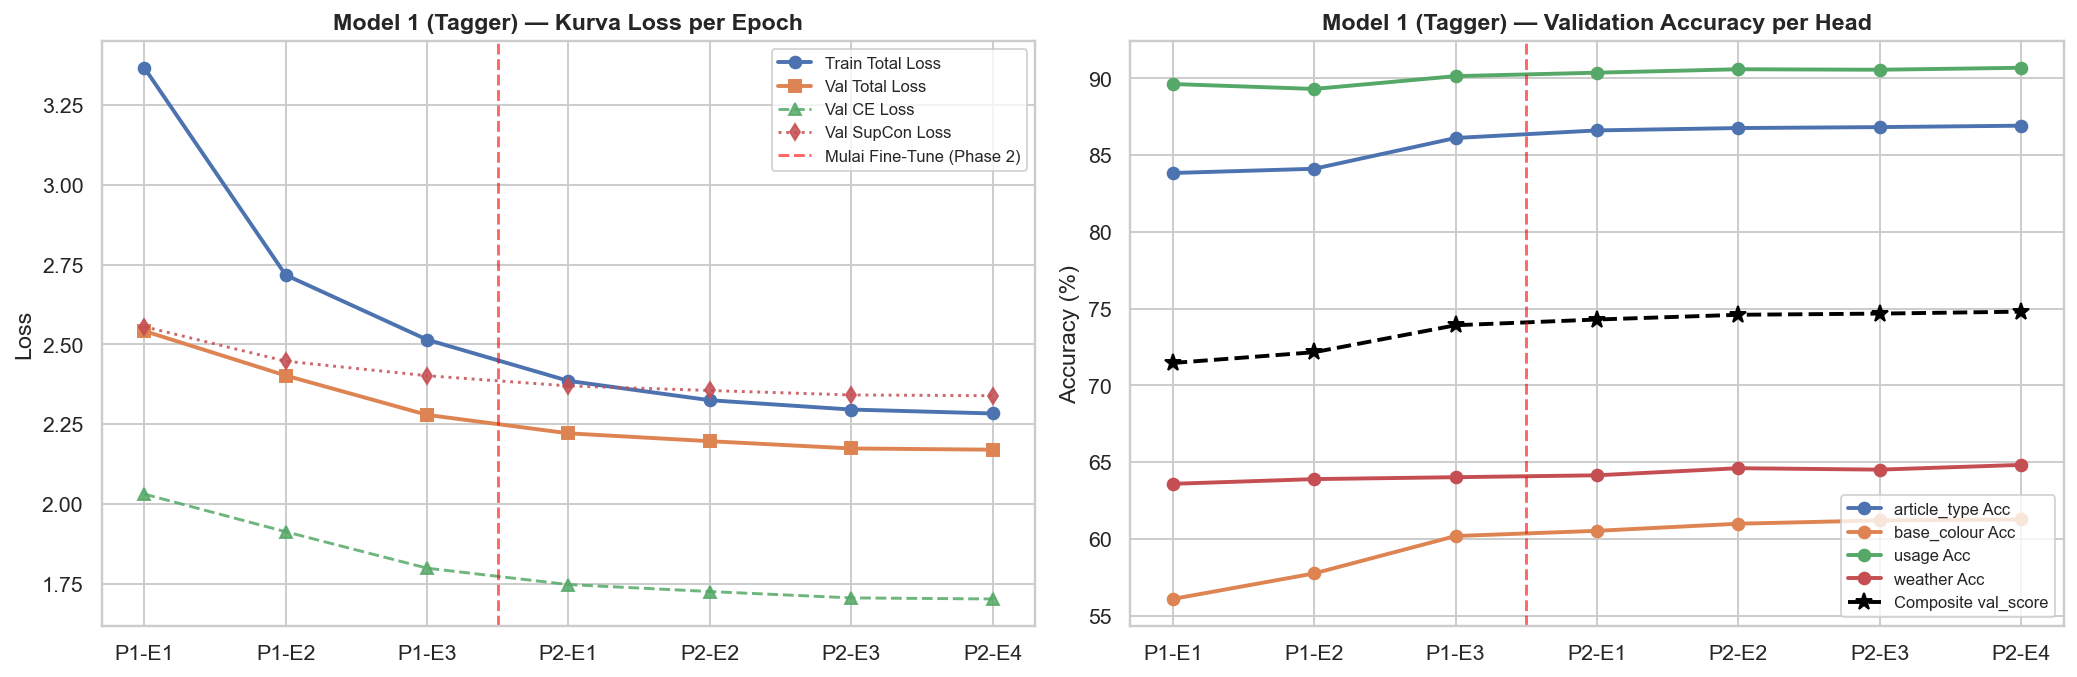

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/model1_training_curves.png


In [2]:
hist = tagger_m["history"]
ep_labels = [f"P{h['phase']}-E{h['epoch']}" for h in hist]
x = np.arange(len(hist))
p1_len = sum(1 for h in hist if h["phase"] == 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 5), dpi=140)

# Loss curves
axes[0].plot(x, [h["train"]["loss"] for h in hist], marker="o", label="Train Total Loss", linewidth=2)
axes[0].plot(x, [h["val"]["loss"] for h in hist], marker="s", label="Val Total Loss", linewidth=2)
axes[0].plot(x, [h["val"]["ce"] for h in hist], marker="^", linestyle="--", label="Val CE Loss", alpha=0.85)
axes[0].plot(x, [h["val"]["supcon"] for h in hist], marker="d", linestyle=":", label="Val SupCon Loss", alpha=0.85)
axes[0].axvline(p1_len - 0.5, color="red", linestyle="--", alpha=0.6, label="Mulai Fine-Tune (Phase 2)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(ep_labels)
axes[0].set_ylabel("Loss")
axes[0].set_title("Model 1 (Tagger) — Kurva Loss per Epoch", fontweight="bold")
axes[0].legend(fontsize=8.5)

# Validation accuracy per head
for head, label in [
    ("article_type_acc", "article_type Acc"),
    ("base_colour_acc", "base_colour Acc"),
    ("usage_acc", "usage Acc"),
    ("weather_acc", "weather Acc"),
]:
    axes[1].plot(x, [h["val"][head] * 100 for h in hist], marker="o", label=label, linewidth=2)
axes[1].plot(x, [h["val_score"] * 100 for h in hist], marker="*", markersize=9, linestyle="--", color="black", label="Composite val_score", linewidth=2)
axes[1].axvline(p1_len - 0.5, color="red", linestyle="--", alpha=0.6)
axes[1].set_xticks(x)
axes[1].set_xticklabels(ep_labels)
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Model 1 (Tagger) — Validation Accuracy per Head", fontweight="bold")
axes[1].legend(fontsize=8.5, loc="lower right")

plt.tight_layout()
fig.savefig(PLOT_DIR / "model1_training_curves.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "model1_training_curves.png"))

## Step E3 — Confusion Matrix Model 1 (Tagger, Split Test)

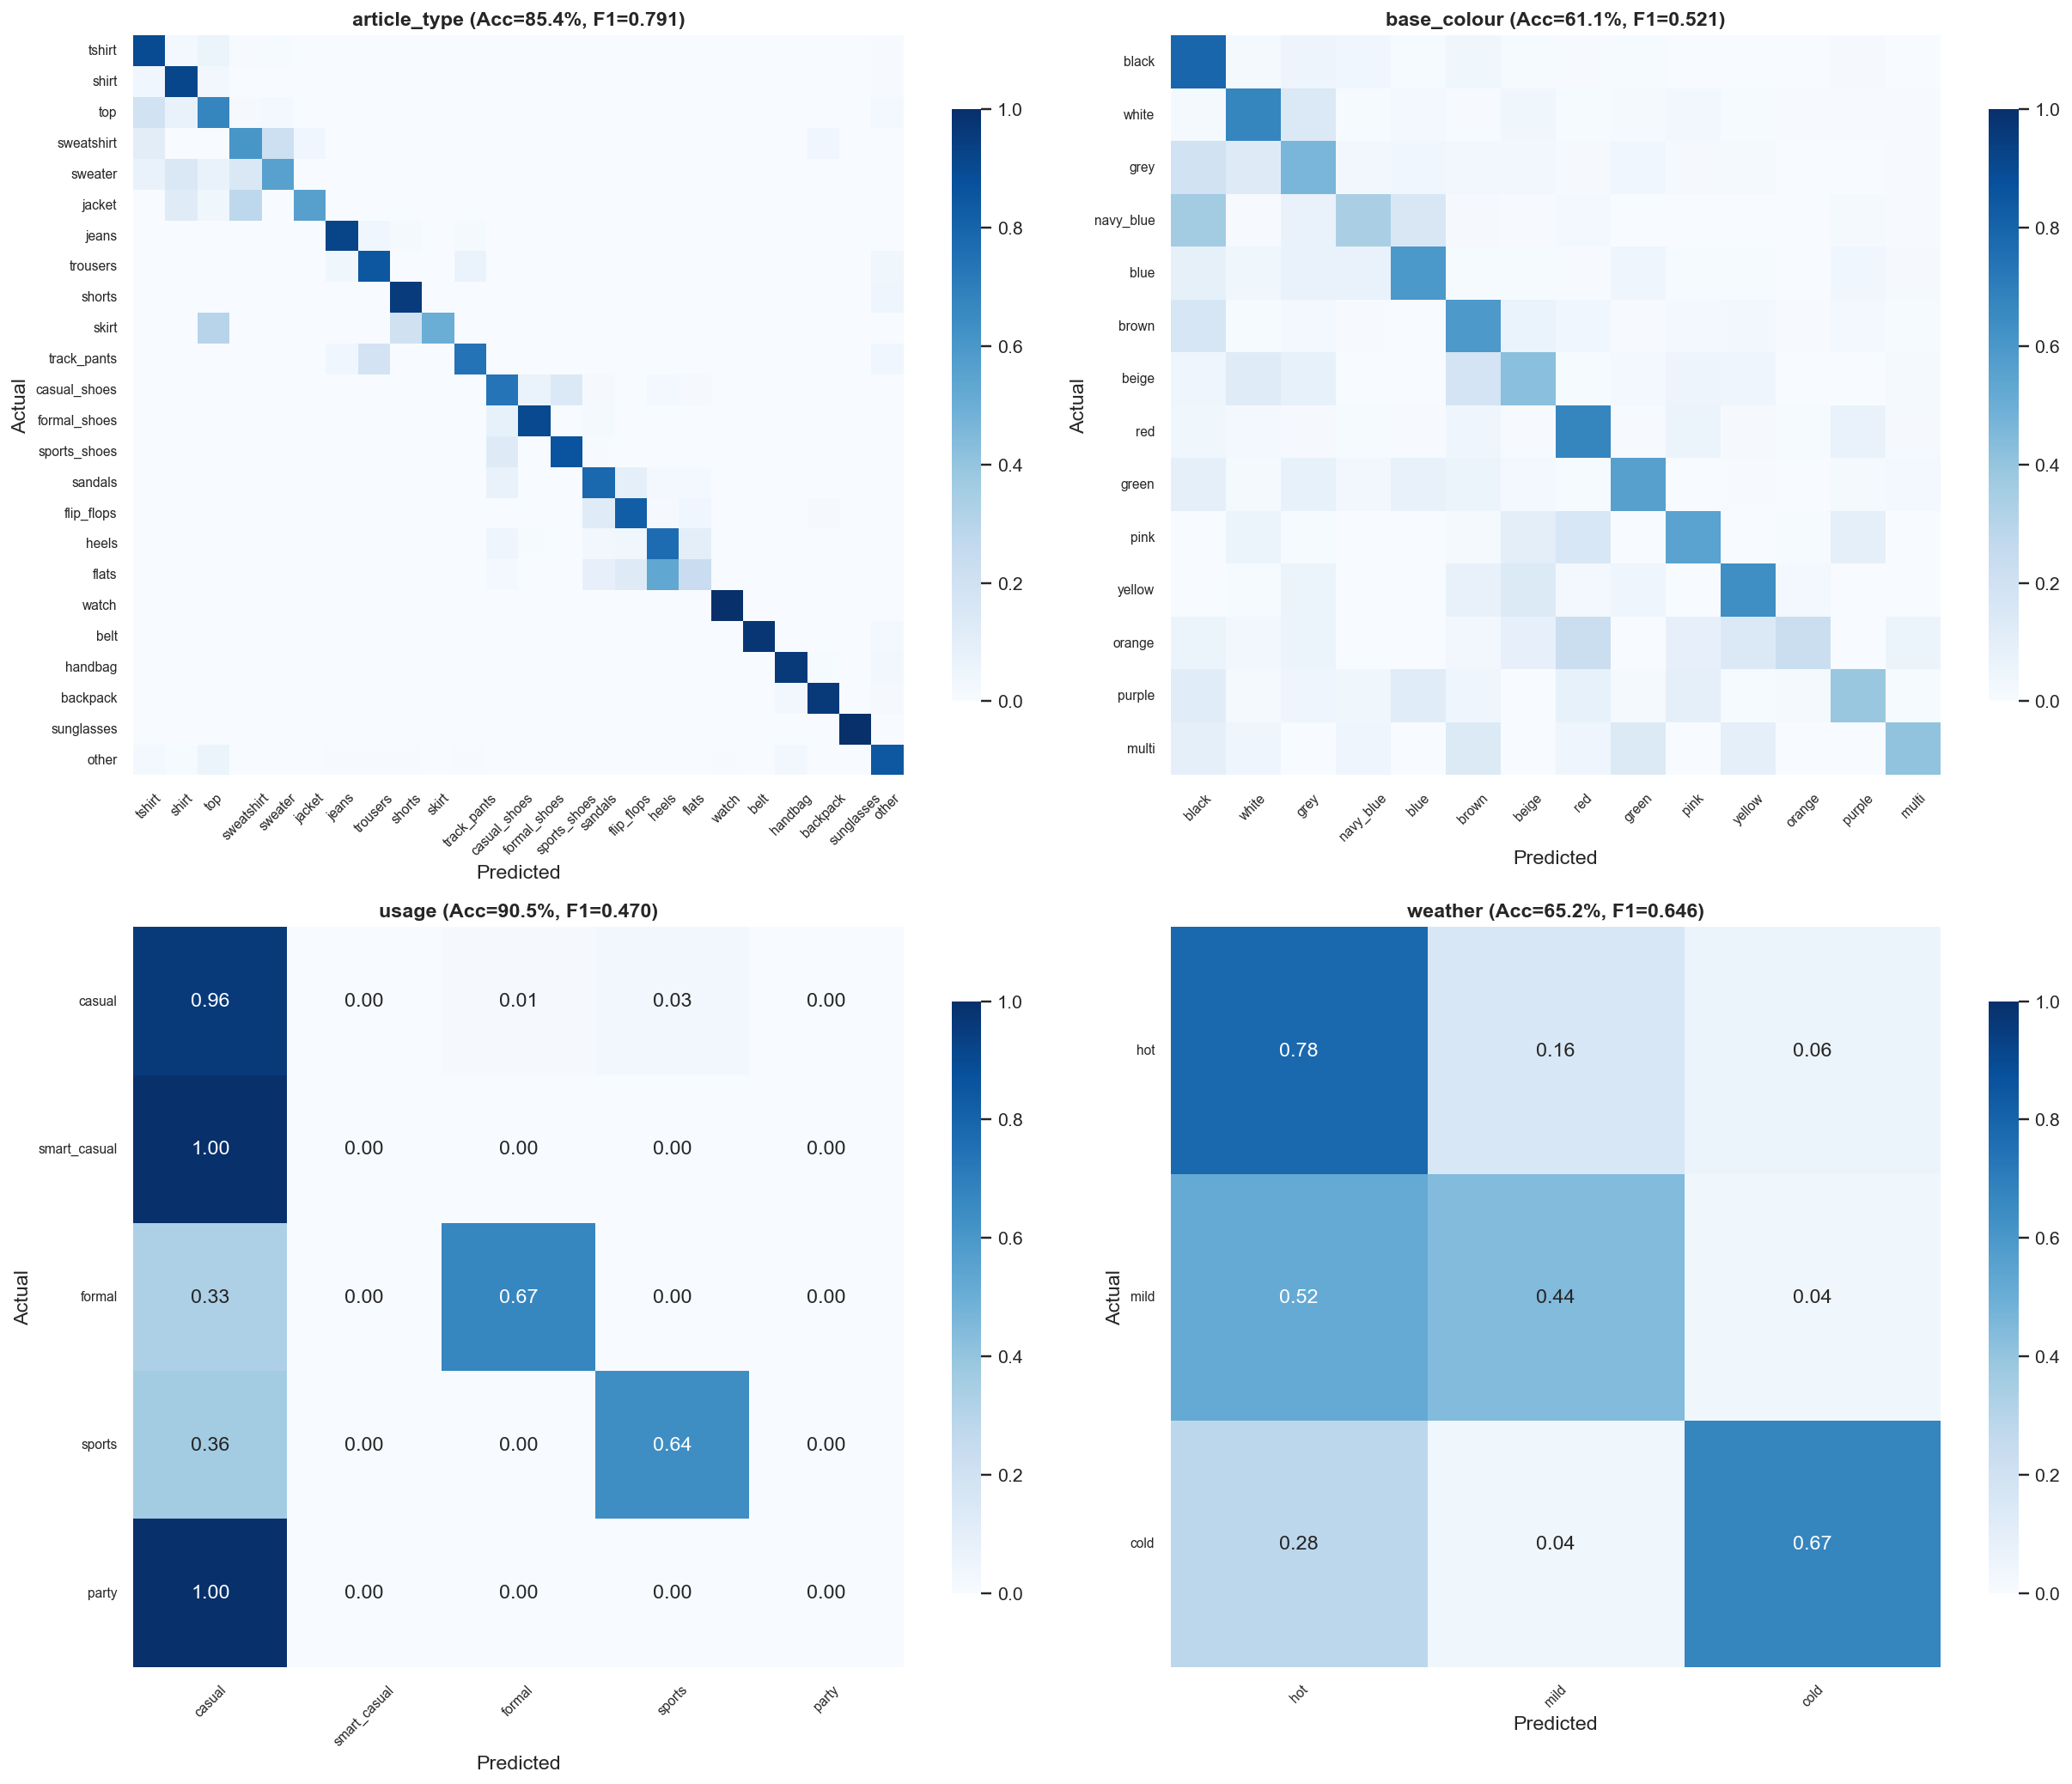

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/model1_confusion_matrices.png


In [3]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import keras
from sklearn.metrics import confusion_matrix

labels_cfg = cu.load_labels()
art_keys = [e["key"] for e in labels_cfg["article_type"]]
col_keys = [e["key"] for e in labels_cfg["base_colour"]]
usg_keys = [e["key"] for e in labels_cfg["usage"]]
wth_keys = ["hot", "mild", "cold"]

test_df = pd.read_csv(cu.fashion_processed_dir() / "splits" / "test.csv")
imgs_mmap = np.load(cu.fashion_processed_dir() / "fashion_128.npy", mmap_mode="r")
tagger_model = keras.models.load_model(ARTIFACTS / "tagger_best.keras", compile=False)

pred_art, pred_col, pred_usg, pred_wth = [], [], [], []
idx_arr = test_df["npy_index"].to_numpy(dtype=np.int64)
for start in range(0, len(idx_arr), 128):
    batch = np.asarray(imgs_mmap[idx_arr[start:start + 128]], dtype=np.float32)
    out = tagger_model(batch, training=False)
    pred_art.append(np.argmax(out["article_type"].numpy(), axis=1))
    pred_col.append(np.argmax(out["base_colour"].numpy(), axis=1))
    pred_usg.append(np.argmax(out["usage"].numpy(), axis=1))
    pred_wth.append(np.argmax(out["weather"].numpy(), axis=1))

pred_art = np.concatenate(pred_art)
pred_col = np.concatenate(pred_col)
pred_usg = np.concatenate(pred_usg)
pred_wth = np.concatenate(pred_wth)

y_art = test_df["article_type"].map({k: i for i, k in enumerate(art_keys)}).to_numpy()
y_col = test_df["base_colour"].map({k: i for i, k in enumerate(col_keys)}).to_numpy()
usg_mask = test_df["usage_valid"].astype(bool).to_numpy()
y_usg = test_df.loc[usg_mask, "usage"].map({k: i for i, k in enumerate(usg_keys)}).to_numpy()
wth_mask = test_df["weather_valid"].astype(bool).to_numpy()
y_wth = test_df.loc[wth_mask, "weather"].map({k: i for i, k in enumerate(wth_keys)}).to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(18, 15), dpi=140)

def plot_cm(ax, y_true, y_pred, keys, title, show_vals=False):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(keys))), normalize="true")
    cm = np.nan_to_num(cm)
    sns.heatmap(
        cm, ax=ax, cmap="Blues", vmin=0, vmax=1,
        xticklabels=keys, yticklabels=keys,
        annot=show_vals, fmt=".2f" if show_vals else "",
        cbar_kws={"shrink": 0.8},
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)

plot_cm(axes[0, 0], y_art, pred_art, art_keys, f"article_type (Acc={t_test['article_type_acc']*100:.1f}%, F1={t_test['article_type_macro_f1']:.3f})", show_vals=False)
plot_cm(axes[0, 1], y_col, pred_col, col_keys, f"base_colour (Acc={t_test['base_colour_acc']*100:.1f}%, F1={t_test['base_colour_macro_f1']:.3f})", show_vals=False)
plot_cm(axes[1, 0], y_usg, pred_usg[usg_mask], usg_keys, f"usage (Acc={t_test['usage_acc']*100:.1f}%, F1={t_test['usage_macro_f1']:.3f})", show_vals=True)
plot_cm(axes[1, 1], y_wth, pred_wth[wth_mask], wth_keys, f"weather (Acc={t_test['weather_acc']*100:.1f}%, F1={t_test['weather_macro_f1']:.3f})", show_vals=True)

plt.tight_layout()
fig.savefig(PLOT_DIR / "model1_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "model1_confusion_matrices.png"))

## Step E4 — Kurva Training, ROC/PR Curve & Confusion Matrix Model 2 (Outfit Scorer)

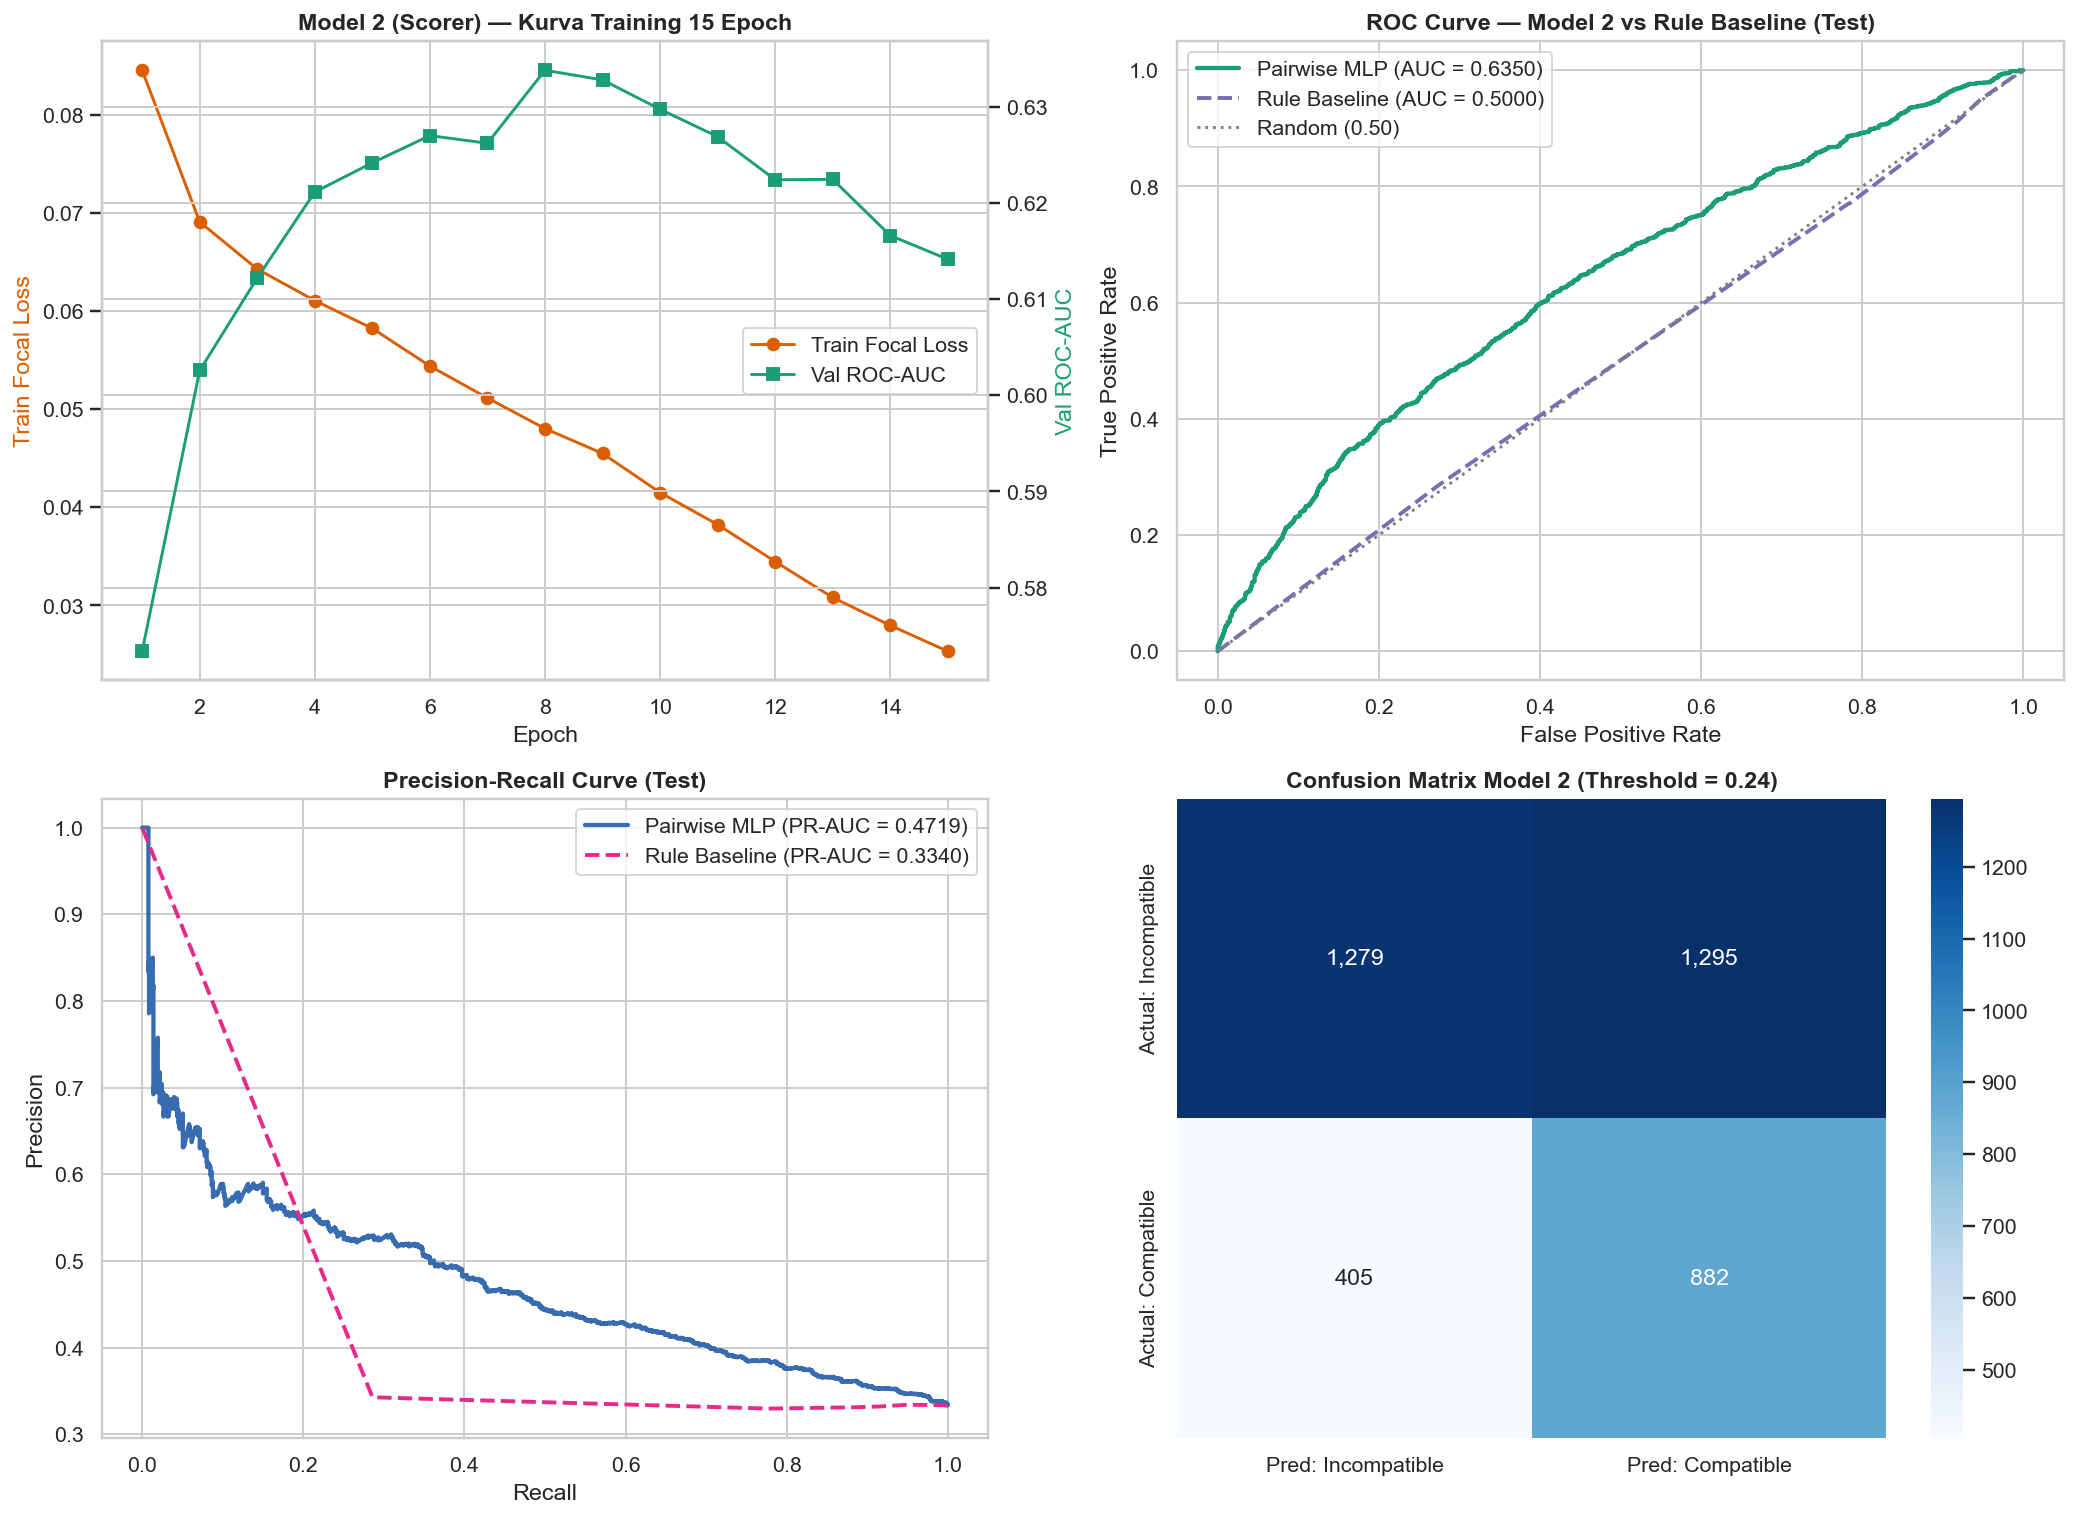

Saved: C:/NEURFIT_PROJECT/ml/artifacts/plots/model2_evaluation_curves.png


In [4]:
from collections import defaultdict
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, roc_auc_score, average_precision_score

# Rekonstruksi input test split Model 2 secara ringan (sama persis dengan Step C2/C4)
processed = cu.fashion_processed_dir()
pseudo_sets = json.loads((processed / "pseudo_sets.json").read_text(encoding="utf-8"))
poly_items = pd.read_csv(processed / "polyvore_items.csv")
arrs = np.load(processed / "polyvore_embeddings.npz", allow_pickle=False)

SLOTS = scorer_meta["slots"]
SLOT_TO_ID = {s: i for i, s in enumerate(SLOTS)}
SEQ_SLOTS = scorer_meta["seq_slots"]
article_keys = [str(x) for x in arrs["article_keys"]]
colour_keys = [str(x) for x in arrs["colour_keys"]]
usage_keys = [str(x) for x in arrs["usage_keys"]]
paths = [str(x) for x in arrs["paths"]]
embs = arrs["embeddings"].astype(np.float32)
art_i = arrs["article"].astype(np.int32)
col_i = arrs["colour"].astype(np.int32)
usg_i = arrs["usage"].astype(np.int32)
path_to_idx = {p: i for i, p in enumerate(paths)}

WARM = {"red", "orange", "yellow", "brown", "beige", "pink"}
COOL = {"blue", "navy_blue", "green", "purple"}
NEUTRAL = {"black", "white", "grey", "navy_blue", "beige", "brown"}

item_slot = {r.image_path: r.slot for r in poly_items.itertuples(index=False)}
slot_ids = np.array([SLOT_TO_ID.get(item_slot.get(p, "pad"), SLOT_TO_ID["pad"]) for p in paths], dtype=np.int32)
emb_mean = np.array(scorer_meta["emb_mean"], dtype=np.float32)
emb_std = np.array(scorer_meta["emb_std"], dtype=np.float32)

def _oh(v, n):
    z = np.zeros(n, dtype=np.float32); z[v] = 1.0; return z

feat_dim = scorer_meta["feature_dim"]
feats = np.zeros((len(paths) + 1, feat_dim), dtype=np.float32)
for i in range(len(paths)):
    c = colour_keys[int(col_i[i])]
    t_id = 0 if c in WARM else (1 if c in COOL else 2)
    feats[i + 1] = np.concatenate([
        (embs[i] - emb_mean) / emb_std,
        _oh(int(slot_ids[i]), len(SLOTS)),
        _oh(int(art_i[i]), len(article_keys)),
        _oh(int(col_i[i]), len(colour_keys)),
        _oh(int(usg_i[i]), len(usage_keys)),
        _oh(t_id, 3),
        np.array([1.0], dtype=np.float32),
    ])

pools = defaultdict(list)
for i in range(len(paths)):
    pools[int(slot_ids[i])].append(i + 1)
pools = {k: np.asarray(sorted(v), dtype=np.int32) for k, v in pools.items()}

rng = np.random.default_rng(1234)
pos_seqs, pos_masks, pos_tpls = [], [], []
neg_seqs, neg_masks, neg_tpls = [], [], []

for outfit in pseudo_sets:
    if outfit["split"] != "test":
        continue
    tpl = outfit["template"]
    slots = SEQ_SLOTS[tpl]
    by_slot = {it["slot"]: it["image_path"] for it in outfit["items"]}
    seq, msk = [], []
    for s in slots:
        p = by_slot.get(s)
        if p is None or p not in path_to_idx:
            seq.append(0); msk.append(0.0)
        else:
            seq.append(path_to_idx[p] + 1); msk.append(1.0)
    seq = np.asarray(seq, dtype=np.int32)
    msk = np.asarray(msk, dtype=np.float32)
    pos_seqs.append(seq); pos_masks.append(msk); pos_tpls.append(tpl)
    valid_pos = np.flatnonzero(msk > 0)
    for _ in range(2):
        kind = str(rng.choice(["random", "replace_one", "replace_two"]))
        neg = seq.copy()
        positions = valid_pos if kind == "random" else rng.choice(valid_pos, size=1 if kind == "replace_one" else min(2, len(valid_pos)), replace=False)
        for pos in positions:
            pool = pools.get(SLOT_TO_ID[slots[int(pos)]])
            if pool is None or len(pool) == 0:
                continue
            for _ in range(5):
                cand = int(rng.choice(pool))
                if cand != int(neg[pos]):
                    neg[pos] = cand; break
        if not np.array_equal(neg, seq):
            neg_seqs.append(neg); neg_masks.append(msk); neg_tpls.append(tpl)

all_seqs = np.stack(pos_seqs + neg_seqs)
all_masks = np.stack(pos_masks + neg_masks)
y_test_s = np.concatenate([np.ones(len(pos_seqs)), np.zeros(len(neg_seqs))])

scorer_model = keras.models.load_model(ARTIFACTS / "outfit_scorer.keras", compile=False)
scores_list = []
for start in range(0, len(all_seqs), 512):
    x_b = feats[all_seqs[start:start + 512]]
    x_b[:, :, -1] = all_masks[start:start + 512]
    scores_list.append(scorer_model(x_b, training=False).numpy().reshape(-1))
y_scores = np.concatenate(scores_list)

def _rule_score(seq, msk, tpl):
    cols, usgs, arts = [], [], []
    for pos, _ in enumerate(SEQ_SLOTS[tpl]):
        item = int(seq[pos])
        if msk[pos] <= 0 or item <= 0:
            continue
        idx = item - 1
        cols.append(colour_keys[int(col_i[idx])])
        usgs.append(usage_keys[int(usg_i[idx])])
        arts.append(article_keys[int(art_i[idx])])
    sc = 0.5
    if sum(c in NEUTRAL for c in cols) >= 2: sc += 0.15
    if len({c for c in cols if c not in NEUTRAL}) >= 3: sc -= 0.20
    if len(usgs) >= 2 and len(set(usgs)) == 1: sc += 0.15
    elif "sports" in usgs and "formal" in usgs: sc -= 0.25
    if "sports" in usgs and "formal_shoes" in arts: sc -= 0.10
    if "formal" in usgs and "sports_shoes" in arts: sc -= 0.10
    return float(np.clip(sc, 0.05, 0.95))

rule_scores = np.array([_rule_score(s, m, t) for s, m, t in zip(all_seqs, all_masks, pos_tpls + neg_tpls)])

# Plot 2x2 Evaluasi Model 2
fig, axes = plt.subplots(2, 2, figsize=(15, 11), dpi=140)

# 1. Training Loss & Val ROC-AUC
s_hist = scorer_m["history"]
eps = [h["epoch"] for h in s_hist]
ax1 = axes[0, 0]
ax1_r = ax1.twinx()
l1 = ax1.plot(eps, [h["train_loss"] for h in s_hist], marker="o", color="#d95f02", label="Train Focal Loss")
l2 = ax1_r.plot(eps, [h["val"]["roc_auc"] for h in s_hist], marker="s", color="#1b9e77", label="Val ROC-AUC")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Train Focal Loss", color="#d95f02")
ax1_r.set_ylabel("Val ROC-AUC", color="#1b9e77")
ax1.set_title("Model 2 (Scorer) — Kurva Training 15 Epoch", fontweight="bold")
lines = l1 + l2
ax1.legend(lines, [l.get_label() for l in lines], loc="center right")

# 2. ROC Curve
fpr_m, tpr_m, _ = roc_curve(y_test_s, y_scores)
fpr_r, tpr_r, _ = roc_curve(y_test_s, rule_scores)
axes[0, 1].plot(fpr_m, tpr_m, linewidth=2.2, color="#1b9e77", label=f"Pairwise MLP (AUC = {roc_auc_score(y_test_s, y_scores):.4f})")
axes[0, 1].plot(fpr_r, tpr_r, linewidth=2, linestyle="--", color="#7570b3", label=f"Rule Baseline (AUC = {roc_auc_score(y_test_s, rule_scores):.4f})")
axes[0, 1].plot([0, 1], [0, 1], linestyle=":", color="gray", label="Random (0.50)")
axes[0, 1].set_xlabel("False Positive Rate")
axes[0, 1].set_ylabel("True Positive Rate")
axes[0, 1].set_title("ROC Curve — Model 2 vs Rule Baseline (Test)", fontweight="bold")
axes[0, 1].legend()

# 3. PR Curve
prec_m, rec_m, _ = precision_recall_curve(y_test_s, y_scores)
prec_r, rec_r, _ = precision_recall_curve(y_test_s, rule_scores)
axes[1, 0].plot(rec_m, prec_m, linewidth=2.2, color="#386cb0", label=f"Pairwise MLP (PR-AUC = {average_precision_score(y_test_s, y_scores):.4f})")
axes[1, 0].plot(rec_r, prec_r, linewidth=2, linestyle="--", color="#e7298a", label=f"Rule Baseline (PR-AUC = {average_precision_score(y_test_s, rule_scores):.4f})")
axes[1, 0].set_xlabel("Recall")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].set_title("Precision-Recall Curve (Test)", fontweight="bold")
axes[1, 0].legend()

# 4. Confusion Matrix pada decision threshold (0.24)
thr = scorer_meta["decision_threshold"]
y_pred_bin = (y_scores >= thr).astype(int)
cm2 = confusion_matrix(y_test_s, y_pred_bin)
sns.heatmap(
    cm2, annot=True, fmt=",d", cmap="Blues", ax=axes[1, 1],
    xticklabels=["Pred: Incompatible", "Pred: Compatible"],
    yticklabels=["Actual: Incompatible", "Actual: Compatible"],
)
axes[1, 1].set_title(f"Confusion Matrix Model 2 (Threshold = {thr:.2f})", fontweight="bold")

plt.tight_layout()
fig.savefig(PLOT_DIR / "model2_evaluation_curves.png", dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", cu.to_posix(PLOT_DIR / "model2_evaluation_curves.png"))